# FineWeb-Edu Llama 124M, Stage 1: 2.5B tokens on a Colab L4

**This is the Stage 1 record.** It's the full-training notebook as it ran on 22–23 November 2026, with its output kept up to the end of the 2.5B branch (step 5,722). The same run continues to 10B tokens as Stage 2, which gets its own notebook when it finishes.

| Stage 1 | |
| --- | --- |
| Model | 124,668,672-parameter Llama: 12 layers, width 768, 12 query / 4 key-value heads, SwiGLU |
| Data | 3.0B FineWeb-Edu tokens: 2.5B at a constant learning rate of 2e-3, then 0.5B decaying linearly to 0 |
| Validation loss | **3.136** on the 512 fixed windows, **3.126** on the full 10.3M-token split |
| Hardware | One Colab L4: 40,350 tokens/s (24% MFU), 20.7 h of training, 20.9 h wall-clock |
| Health | No loss-spike rollbacks. One gradient-norm spike near the end of warmup, recovered by step 300; no clipping after step 400 |

Sections 8 and 9 explain the compute math and show the results.

**Why an L4.** The plan was an A100, but Colab assigned an L4 every time. The L4 uses about a third of the A100's compute units per hour, so the cost per token is about the same, but it's 3–4 times slower: Stage 1 took about 21 hours instead of about 6.

---

The notebook trains the 124,668,672-parameter Llama of [Track 2](../../README.md#3-track-2-a-124m-llama-on-fineweb-edu) on about 10B FineWeb-Edu tokens. It uses the setup that [the LR sweep](CS336_FineWebEdu_Llama124M_LR_Sweep.ipynb) tested, with the peak learning rate it chose (**2e-3**). Training runs in as many Colab sessions as it takes: a checkpoint on Drive is replaced every hour, and **Run all** continues from it.

| Step | Runtime | What it does |
| --- | --- | --- |
| 1. Token cache | **CPU** (first time only) | Extends the sweep's cache to all of `sample/10BT`: the same tokenizer, validation split and first two files, plus the other 11 training files, one part per file. Resumable file by file |
| 2. Self-check | A100 or L4 | Once per GPU type: the batch sampler is deterministic, and both a Drive checkpoint and an in-memory snapshot resume to identical losses |
| 3. Probe | A100 or L4 | Picks the fastest micro-batch that fits and estimates the remaining time and compute units |
| 4. Training | A100 or L4 | Warmup–stable–decay (WSD) to 10B tokens, with a finished 2.5B model branched off on the way |
| 5. Results | any | Curves, milestones, comparison with the sweep, and files to commit |

### How to run it

1. **First time:** choose **Runtime → Change runtime type → CPU** and select **Runtime → Run all**. The notebook tokenizes the 11 missing files (about 8.3B tokens) into `token_cache_full/` on Drive and stops. It prints the encoding speed every 100M tokens. Each finished file is saved, so a disconnect only loses the file in progress: reconnect and **Run all** again. (This run's cache took 1 h 40 min.)
2. **Then:** switch to an **A100**, or an **L4** if no A100 is available, and select **Run all**. Approve the two Google sign-in prompts (Drive, and the Drive API for emptying the notebook's own old checkpoints from the trash).
3. **To stop:** select **Runtime → Interrupt execution**. The notebook finishes the current step (a few seconds), saves a checkpoint and stops.
4. **To continue**, after an interrupt, a disconnect or the end of a runtime: reconnect and select **Run all** with the same `RUN_NAME`. Training resumes from the last checkpoint, which is at most an hour old. Google AI Pro doesn't run notebooks in the background, so keep the tab open while it trains.

### The schedule

| Phase | Steps | Tokens | Learning rate |
| --- | ---: | ---: | --- |
| Warmup | 1–250 | 0.13B | 0 → 2e-3, linear |
| Stable | 251–4,768 | 2.5B | 2e-3 |
| → **2.5B branch (Stage 1)** | 4,769–5,722 | +0.5B | 2e-3 → 0, linear. The finished 2.5B model |
| Stable, continued from step 4,768 (Stage 2) | 4,769–15,258 | 8.0B | 2e-3 |
| Final decay (Stage 2) | 15,259–19,073 | 10.0B | 2e-3 → 0, linear |

At step 4,768 the notebook keeps a permanent copy of the checkpoint (the *pre-decay* checkpoint) and runs the branch from it. The main run then continues from the same checkpoint, so the branch's decay never touches it. `TOTAL_STEPS` can still be lowered at any point before the final decay starts, for example to finish sooner. The final decay always covers the last 20% of the run.

### Time and compute units

Each step is 524,288 tokens.

| GPU | Speed | Whole plan (20,027 steps, 10.5B tokens) | Compute units |
| --- | ---: | ---: | ---: |
| A100 40 GB | ~130–150k tokens/s (expected) | ~20–22 h | ~110–120 at ~5.4 units/h |
| L4 | **40,350 tokens/s (measured in this run)** | ~72 h | ~120 at ~1.7 units/h |

A session can switch GPUs: the micro-batch adapts, and the effective batch doesn't change. Compute-unit rates come from Colab's resources panel and change over time.

**Drive usage.** The full cache takes about 20 GB. Checkpoints take 1.4 GB each: one rolling checkpoint, plus the permanent pre-decay checkpoint. Each finished model takes 0.23 GB in FP16.

## 0. Settings

Everything you might change lives in this cell. Leave the model, batch, data and learning-rate settings alone: a checkpoint refuses to load under different ones. `TOTAL_STEPS` and `FINAL_DECAY_FRACTION` are the exceptions, and can change until the final decay starts.

In [1]:
# ---- Run control ----
PROJECT_DIR_NAME = 'CS336_FineWebEdu_Llama124M'   # the same Drive folder as the sweep
RUN_NAME = 'full_v1'               # reuse the name to resume; change it to start a new run
CHECKPOINT_EVERY_SECONDS = 3600    # one rolling checkpoint on Drive, replaced every hour
MAX_HOURS_THIS_SESSION = None      # e.g. 11.5: checkpoint and stop before the runtime limit
STOP_AFTER_BRANCH = False          # True: stop once the 2.5B model is finished
RUN_SELF_CHECK = True              # skipped automatically once it has passed on this GPU type
REPROBE = False                    # True measures the micro-batch again on this GPU type
PURGE_DRIVE_TRASH = True           # permanently delete this notebook's own trashed checkpoints only
ALLOW_BUILD_ON_GPU = False         # tokenizing is CPU work; build on a CPU runtime

# ---- Data ----
DATASET = 'HuggingFaceFW/fineweb-edu'
DATASET_SUBSET = 'sample/10BT'
TRAIN_FILE_COUNT = None            # None: every file except the last, which holds validation
VOCAB_SIZE = 32_000
EOS_TOKEN = '<|endoftext|>'
TOKENIZER_SHA256_PREFIX = 'ffd28a61329a6407'   # the sweep's tokenizer; any other is refused

# ---- Model and optimizer: the same as the sweep ----
CONTEXT = 1024
EFFECTIVE_BATCH = 512              # 512 x 1,024 = 524,288 tokens per step
PEAK_LR = 2e-3                     # chosen by lr_sweep_v1
WARMUP_STEPS = 250
WEIGHT_DECAY = 0.1
BETAS = (0.9, 0.95)
GRAD_CLIP = 1.0
SEED = 336

# ---- WSD schedule ----
TOTAL_STEPS = 19_073               # 10.0B tokens
FINAL_DECAY_FRACTION = 0.2         # linear decay to zero over the last 20% of the steps
BRANCH_AT_STEP = 4_768             # 2.5B tokens: keep this checkpoint and branch a short decay from it
BRANCH_DECAY_STEPS = 954           # about 0.5B tokens; 0 skips the branch

# ---- Evaluation, logging and the spike guard ----
EVAL_EVERY = 250                   # steps between validation passes
EARLY_EVAL_STEPS = (50, 100, 150, 200, 300, 350, 400)   # extra passes, compared with the sweep
VAL_WINDOWS = 512                  # the sweep's 512 validation windows of 1,024 tokens
LOG_EVERY = 10
SAMPLE_EVERY = 1000
SAMPLE_PROMPTS = ('The water cycle begins when', 'In mathematics, a prime number is',
                  'The French Revolution began')
SNAPSHOT_EVERY = 100               # in-memory copies of the weights, for rolling back a loss spike
SPIKE_THRESHOLD = 0.3              # nats above the running average of the training loss
SPIKE_PATIENCE = 5                 # consecutive steps above it before rolling back
SPIKE_GUARD_FROM = 50              # the running average starts at this step
MAX_ROLLBACKS = 4                  # then stop and ask for a decision
PROBE_TIMED_STEPS = 2
PROBE_HEADROOM_GIB = 1.0

## 1. Runtime, Drive and GPU profile

Training needs bf16, so it runs on an A100, L4, H100 or any GPU with compute capability 8.0 or newer. A T4 is refused. A CPU runtime is only used to build the token cache. The micro-batches the probe tries depend on the GPU's memory.

In [2]:
import copy
import gc
import hashlib
import itertools
import json
import math
import os
import shutil
import signal
import sys
import time
from collections import deque
from dataclasses import asdict, dataclass
from pathlib import Path

os.environ.setdefault('TOKENIZERS_PARALLELISM', 'true')

import logging
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from google.colab import drive

logging.getLogger('google_auth_httplib2').setLevel(logging.ERROR)


class StopHere(Exception):
    'Raised on purpose to stop Run all with an explanation.'


drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive') / PROJECT_DIR_NAME
SWEEP_CACHE = DRIVE_ROOT / 'token_cache'           # built by the sweep notebook
CACHE_DRIVE = DRIVE_ROOT / 'token_cache_full'
CACHE_LOCAL = Path('/content/token_cache_full')
RUN_DIR = DRIVE_ROOT / 'runs' / RUN_NAME
CKPT_DIR = RUN_DIR / 'checkpoints'                 # the rolling checkpoint
PREDECAY_DIR = RUN_DIR / 'pre_decay'               # the permanent step-4,768 checkpoint
MODELS_DIR = RUN_DIR / 'models'                    # finished FP16 models
SMOKE_DIR = DRIVE_ROOT / 'smoke_tests'
LOCAL_TMP = Path('/content/ckpt_tmp')
FILE_PREFIX = 'cs336-llama124m-'   # the trash purge only touches files with this prefix
for folder in (DRIVE_ROOT, RUN_DIR, CKPT_DIR, PREDECAY_DIR, MODELS_DIR, SMOKE_DIR, LOCAL_TMP):
    folder.mkdir(parents=True, exist_ok=True)

PEAK_BF16_FLOPS = {'a100': 312e12, 'h100': 989e12, 'l4': 121e12}
UNITS_PER_HOUR = {'a100': 5.4, 'l4': 1.7}          # approximate; see Colab's resources panel


def detect_runtime():
    if not torch.cuda.is_available():
        return torch.device('cpu'), 'cpu', (), 'CPU'
    name = torch.cuda.get_device_name(0)
    major, minor = torch.cuda.get_device_capability(0)
    upper = name.upper()
    if 'A100' in upper:
        tag = 'a100'
    elif 'H100' in upper:
        tag = 'h100'
    elif 'L4' in upper:
        tag = 'l4'
    else:
        tag = 'gpu-' + ''.join(ch if ch.isalnum() else '-' for ch in name.lower()).strip('-')
    if major < 8:
        tag = 'no-bf16'
    memory_gib = torch.cuda.get_device_properties(0).total_memory / 2**30
    if memory_gib >= 70:
        tag += '-80gb' if tag == 'a100' else ''
        microbatches = (64, 32, 16)
    elif memory_gib >= 35:
        microbatches = (32, 16, 8)
    else:
        microbatches = (16, 8, 4)
    return torch.device('cuda'), tag, microbatches, f'{name} (compute capability {major}.{minor})'


DEVICE, GPU_TAG, MICROBATCH_CANDIDATES, GPU_NAME = detect_runtime()
USE_COMPILE = DEVICE.type == 'cuda'
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    free, total = torch.cuda.mem_get_info()
    print(f'{GPU_NAME} | {free / 2**30:.1f} of {total / 2**30:.1f} GiB free')
else:
    print('CPU runtime: this session can build the token cache but cannot train.')
print(f'PyTorch {torch.__version__} | {os.cpu_count()} CPU cores | '
      f'{shutil.disk_usage("/content").free / 2**30:.0f} GiB free on the VM disk')
print(f'Run folder: {RUN_DIR}')


def require_training_gpu():
    if DEVICE.type != 'cuda':
        raise StopHere('Switch to an A100 runtime (Runtime → Change runtime type) and Run all again.')
    if GPU_TAG == 'no-bf16':
        raise StopHere(f'{GPU_NAME} has no bf16. Track 2 trains on an A100, L4 or H100.')


def gpu_sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()


def gpu_free_bytes():
    return torch.cuda.mem_get_info()[0] if DEVICE.type == 'cuda' else 0


def gpu_reset_peak():
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()


def gpu_peak_bytes():
    return torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else 0


def read_json(path):
    path = Path(path)
    return json.loads(path.read_text(encoding='utf-8')) if path.is_file() else None


def write_json(path, data):
    path = Path(path)
    tmp = path.with_name(path.name + '.partial')
    tmp.write_text(json.dumps(data, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    os.replace(tmp, path)


def utc_now():
    return time.strftime('%Y-%m-%d %H:%M UTC', time.gmtime())

Mounted at /content/drive
NVIDIA L4 (compute capability 8.9) | 21.8 of 22.0 GiB free
PyTorch 2.14.1+cu130 | 12 CPU cores | 236 GiB free on the VM disk
Run folder: /content/drive/MyDrive/CS336_FineWebEdu_Llama124M/runs/full_v1


### Drive trash purge

Files deleted or replaced through Colab's Drive mount can move to the Drive trash, where they still count against your quota. With a 1.5 GB checkpoint every hour, that adds up. After each checkpoint the notebook asks the Drive API for **trashed files whose names start with `cs336-llama124m-`** and deletes those permanently. Nothing else in your trash is touched. Set `PURGE_DRIVE_TRASH = False` to skip this; the smoke test then reports whether the trash is growing.

In [3]:
class DriveTrash:
    def __init__(self, enabled):
        self.enabled = enabled
        self.service = None

    def connect(self):
        if not self.enabled or self.service is not None:
            return
        from google.colab import auth
        from googleapiclient.discovery import build
        auth.authenticate_user()
        self.service = build('drive', 'v3', cache_discovery=False)

    def quota(self):
        if self.service is None:
            return None
        q = self.service.about().get(fields='storageQuota').execute()['storageQuota']
        return {key: int(q[key]) for key in ('usage', 'usageInDriveTrash') if key in q}

    def purge(self):
        # Permanently deletes this notebook's own files from the trash. Returns the number deleted.
        if self.service is None:
            return 0
        deleted, token = 0, None
        try:
            while True:
                page = self.service.files().list(
                    q="trashed = true and 'me' in owners", spaces='drive',
                    fields='nextPageToken, files(id, name)', pageSize=1000, pageToken=token,
                ).execute()
                for item in page.get('files', []):
                    if item['name'].startswith(FILE_PREFIX):
                        self.service.files().delete(fileId=item['id']).execute()
                        deleted += 1
                token = page.get('nextPageToken')
                if not token:
                    return deleted
        except Exception as error:  # a failed purge never stops training
            print(f'Drive trash purge skipped: {error}')
            return deleted


DRIVE_TRASH = DriveTrash(PURGE_DRIVE_TRASH and DEVICE.type == 'cuda')
DRIVE_TRASH.connect()
if DRIVE_TRASH.service is not None:
    usage = DRIVE_TRASH.quota()
    print(f'Drive API connected | used {usage["usage"] / 2**30:.1f} GiB, '
          f'{usage.get("usageInDriveTrash", 0) / 2**30:.2f} GiB of it in the trash')

Drive API connected | used 24.3 GiB, 1.39 GiB of it in the trash


## 2. Token cache: extend the sweep's cache to all of `sample/10BT`

The sweep cache in `token_cache/` holds the tokenizer, the validation split and the first two training files (1.51B tokens). The full run needs the whole sample, so `token_cache_full/` reuses all of that and adds the rest:

| Part | Source | Tokens |
| --- | --- | ---: |
| `tokenizer.json`, `valid.u16` | copied from `token_cache/`, unchanged | 10.3M validation |
| `train-000-001.u16` | the sweep's `train.u16` (files 0 and 1), copied | 1.51B |
| `train-002.u16` … `train-012.u16` | tokenized here, one part per file | ~0.76B each |

Same dataset revision, tokenizer and validation windows as the sweep, so the losses are directly comparable. The last file of the sample stays reserved for validation.

**Building** happens on a CPU runtime and is resumable. Each file is downloaded, encoded on the VM disk, copied to Drive, and only then recorded in `manifest.json`. A disconnect loses at most the file in progress. The manifest is marked complete after the last file.

**Loading** on a GPU runtime copies the cache (about 20 GB, roughly 5–8 minutes) to the VM disk, because random reads over the Drive mount are slow. Then it checks every file: the tokenizer's SHA-256 against the manifest and the sweep, each file's size and fingerprint, token IDs below 32,000, and a plausible average document length.

In [4]:
from tokenizers import Tokenizer


class CacheError(Exception):
    pass


def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def fingerprint(path, chunk=8 * 2**20):
    # Size plus the first and last 8 MiB: fast, and catches truncated or mixed-up files.
    size = path.stat().st_size
    digest = hashlib.sha256(str(size).encode())
    with open(path, 'rb') as f:
        digest.update(f.read(chunk))
        if size > chunk:
            f.seek(max(chunk, size - chunk))
            digest.update(f.read(chunk))
    return digest.hexdigest()


def check_tokenizer(path, expected_sha, expected_eos_id):
    text = Path(path).read_text(encoding='utf-8')
    sha = sha256_bytes(text.encode('utf-8'))
    if sha != expected_sha:
        raise CacheError(f'{path} does not match the SHA-256 in its manifest')
    if not sha.startswith(TOKENIZER_SHA256_PREFIX):
        raise CacheError(f'tokenizer SHA-256 {sha[:16]}… is not the sweep tokenizer {TOKENIZER_SHA256_PREFIX}…')
    tokenizer = Tokenizer.from_str(text)
    if tokenizer.get_vocab_size() != VOCAB_SIZE or tokenizer.token_to_id(EOS_TOKEN) != expected_eos_id:
        raise CacheError('tokenizer vocabulary or EOS ID does not match the manifest')
    return tokenizer


def check_stream(path, tokens, expected_fingerprint, eos_id, blocks=64, block=16_384):
    # Size, fingerprint and content checks. Reads `blocks` contiguous blocks rather than
    # scattered tokens, so it's also quick on the Drive mount.
    path = Path(path)
    if not path.is_file():
        raise CacheError(f'{path.name} is missing')
    if path.stat().st_size != tokens * 2:
        raise CacheError(f'{path.name} has {path.stat().st_size:,} bytes, expected {tokens * 2:,}')
    if fingerprint(path) != expected_fingerprint:
        raise CacheError(f'{path.name} fingerprint does not match the manifest')
    stream = np.memmap(path, dtype=np.uint16, mode='r')
    if len(stream) <= 2 * CONTEXT + 1:
        raise CacheError(f'{path.name} is shorter than two training windows')
    rng = np.random.default_rng(len(stream))
    starts = rng.integers(0, max(1, len(stream) - block), size=blocks)
    sample = np.concatenate([np.asarray(stream[s:s + block]) for s in starts])
    if int(sample.max()) >= VOCAB_SIZE:
        raise CacheError(f'{path.name} contains token IDs outside the vocabulary')
    eos_share = float((sample == eos_id).mean())
    mean_doc = 1 / eos_share if eos_share else float('inf')
    if not 50 <= mean_doc <= 20_000:
        raise CacheError(f'{path.name}: implausible mean document length of {mean_doc:,.0f} tokens')
    return stream, mean_doc


def expected_fields():
    return {'dataset': DATASET, 'subset': DATASET_SUBSET, 'vocab_size': VOCAB_SIZE,
            'eos_token': EOS_TOKEN, 'dtype': 'uint16'}


def check_fields(manifest, label):
    for key, value in expected_fields().items():
        if manifest.get(key) != value:
            raise CacheError(f'{label} manifest {key} = {manifest.get(key)!r}, expected {value!r}')


def verify_cache(folder, quiet=False):
    # Checks a complete full cache in `folder`. Returns (manifest, tokenizer, valid, parts).
    folder = Path(folder)
    manifest = read_json(folder / 'manifest.json')
    if manifest is None or not manifest.get('complete'):
        raise CacheError(f'no complete manifest.json in {folder}')
    if manifest.get('format_version') != 2:
        raise CacheError(f'manifest format_version {manifest.get("format_version")}, expected 2')
    check_fields(manifest, 'full cache')
    tokenizer = check_tokenizer(folder / 'tokenizer.json', manifest['tokenizer_sha256'], manifest['eos_id'])
    info = manifest['valid']
    valid, _ = check_stream(folder / info['path'], info['tokens'], info['fingerprint'], manifest['eos_id'])
    covered = [name for part in manifest['parts'] for name in part['files']]
    if covered != manifest['train_files']:
        raise CacheError('the parts do not cover the training files in order')
    parts = []
    for part in manifest['parts']:
        stream, mean_doc = check_stream(folder / part['path'], part['tokens'], part['fingerprint'],
                                        manifest['eos_id'])
        parts.append(stream)
    if not quiet:
        total = sum(p['tokens'] for p in manifest['parts'])
        print(f'  {len(parts)} training parts, {total:,} tokens from {len(covered)} files; '
              f'validation {info["tokens"]:,} tokens')
        rng = np.random.default_rng(0)
        for label, stream in (('train', parts[int(rng.integers(len(parts)))]), ('valid', valid)):
            start = int(rng.integers(0, len(stream) - 80))
            snippet = tokenizer.decode(stream[start:start + 80].astype(np.int64).tolist())
            print(f'    {label}: "{snippet[:200].strip()}"')
        print(f'  tokenizer SHA-256 {manifest["tokenizer_sha256"][:16]}… | dataset revision '
              f'{manifest["revision"][:12]} | completed {manifest["completed_utc"]}')
    return manifest, tokenizer, valid, parts


def cache_files(manifest):
    return ['tokenizer.json', manifest['valid']['path']] + [p['path'] for p in manifest['parts']]


def copy_file(source, target):
    # Copy as .partial, check the size, then rename, so an interrupted copy never looks complete.
    partial = target.with_name(target.name + '.partial')
    shutil.copyfile(source, partial)
    if partial.stat().st_size != source.stat().st_size:
        raise CacheError(f'copy of {source.name} is incomplete')
    os.replace(partial, target)

In [5]:
def hf_token():
    try:
        from google.colab import userdata
        return userdata.get('HF_TOKEN')
    except Exception:
        return None  # anonymous downloads work, with lower rate limits


def parquet_text_batches(path, batch_size=1024):
    import pyarrow.parquet as pq
    for batch in pq.ParquetFile(path).iter_batches(batch_size=batch_size, columns=['text']):
        yield batch.column(0).to_pylist()


def encode_parquet(tokenizer, eos_id, path, out_path, label=''):
    # The sweep's encoder: every document followed by <|endoftext|>, written as uint16.
    tokens = documents = 0
    started = time.time()
    next_report = 100_000_000
    with open(out_path, 'wb') as out:
        for texts in parquet_text_batches(path):
            encodings = tokenizer.encode_batch(texts)  # parallel across CPU cores
            ids = np.fromiter(
                itertools.chain.from_iterable(itertools.chain(e.ids, (eos_id,)) for e in encodings),
                dtype=np.uint16,
            )
            ids.tofile(out)
            tokens += ids.size
            documents += len(texts)
            if tokens >= next_report:
                rate = tokens / (time.time() - started)
                print(f'    {label}: {tokens / 1e6:,.0f}M tokens, {rate / 1e6:.2f}M tokens/s')
                next_report += 100_000_000
    return tokens, documents


def sweep_cache_manifest():
    manifest = read_json(SWEEP_CACHE / 'manifest.json')
    if manifest is None:
        raise StopHere(f'The sweep cache is missing from {SWEEP_CACHE}. '
                       'Build it with CS336_FineWebEdu_Llama124M_LR_Sweep first.')
    check_fields(manifest, 'sweep cache')
    return manifest


def start_full_cache():
    # A new full cache: the sweep's tokenizer, validation split and first two files, plus the
    # list of every training file at the same dataset revision.
    from huggingface_hub import HfApi
    sweep = sweep_cache_manifest()
    revision = sweep['revision']
    files = sorted(f for f in HfApi(token=hf_token()).list_repo_files(DATASET, repo_type='dataset', revision=revision)
                   if f.startswith(DATASET_SUBSET + '/') and f.endswith('.parquet'))
    valid_file = files[-1]
    train_files = files[:-1] if TRAIN_FILE_COUNT is None else files[:TRAIN_FILE_COUNT]
    if valid_file in train_files:
        raise CacheError('the validation file would also be used for training')
    sweep_train, sweep_valid = sweep['splits']['train'], sweep['splits']['valid']
    if sweep_valid['files'] != [valid_file] or train_files[:len(sweep_train['files'])] != sweep_train['files']:
        raise CacheError(f'the sweep cache used {sweep_train["files"]} and {sweep_valid["files"]}, '
                         f'which do not line up with {DATASET_SUBSET} at revision {revision[:12]}')
    print(f'{DATASET} {DATASET_SUBSET} at revision {revision[:12]}: {len(files)} files, '
          f'{len(train_files)} for training, {valid_file} for validation')

    CACHE_DRIVE.mkdir(parents=True, exist_ok=True)
    check_tokenizer(SWEEP_CACHE / 'tokenizer.json', sweep['tokenizer_sha256'], sweep['eos_id'])
    copies = (('tokenizer.json', 'tokenizer.json'), ('valid.u16', 'valid.u16'), ('train.u16', 'train-000-001.u16'))
    for source_name, target_name in copies:
        started = time.time()
        copy_file(SWEEP_CACHE / source_name, CACHE_DRIVE / target_name)
        print(f'  copied the sweep\'s {source_name} as {target_name} in {time.time() - started:.0f}s')
    manifest = {
        'format_version': 2, **expected_fields(), 'revision': revision,
        'eos_id': sweep['eos_id'], 'tokenizer_sha256': sweep['tokenizer_sha256'],
        'tokenizer': sweep['tokenizer'], 'tokenizer_train_documents': sweep['tokenizer_train_documents'],
        'train_files': train_files,
        'valid': {'path': 'valid.u16', 'files': sweep_valid['files'], 'tokens': sweep_valid['tokens'],
                  'documents': sweep_valid['documents'], 'fingerprint': sweep_valid['fingerprint']},
        'parts': [{'path': 'train-000-001.u16', 'files': sweep_train['files'], 'tokens': sweep_train['tokens'],
                   'documents': sweep_train['documents'], 'fingerprint': sweep_train['fingerprint'],
                   'source': 'sweep cache'}],
        'complete': False, 'started_utc': utc_now(),
    }
    write_json(CACHE_DRIVE / 'manifest.json', manifest)
    return manifest


def build_cache():
    # Resumable: every finished file is on Drive and in the manifest before the next one starts.
    from huggingface_hub import hf_hub_download
    manifest = read_json(CACHE_DRIVE / 'manifest.json') or start_full_cache()
    tokenizer = check_tokenizer(CACHE_DRIVE / 'tokenizer.json', manifest['tokenizer_sha256'], manifest['eos_id'])
    eos_id = manifest['eos_id']
    staging, download_dir = Path('/content/full_cache_build'), Path('/content/fineweb_download')
    staging.mkdir(parents=True, exist_ok=True)
    done = {name for part in manifest['parts'] for name in part['files']}
    todo = [name for name in manifest['train_files'] if name not in done]
    print(f'{len(done)} of {len(manifest["train_files"])} training files are in the cache; {len(todo)} to go')
    for name in todo:
        index = manifest['train_files'].index(name)
        part_name = f'train-{index:03d}.u16'
        started = time.time()
        path = Path(hf_hub_download(DATASET, name, repo_type='dataset', revision=manifest['revision'],
                                    local_dir=download_dir, token=hf_token()))
        print(f'  downloaded {name}: {path.stat().st_size / 2**30:.2f} GiB in {time.time() - started:.0f}s')
        started = time.time()
        local = staging / part_name
        tokens, documents = encode_parquet(tokenizer, eos_id, path, local, label=name)
        print(f'  encoded {name}: {tokens:,} tokens from {documents:,} documents in {time.time() - started:.0f}s')
        part = {'path': part_name, 'files': [name], 'tokens': tokens, 'documents': documents,
                'fingerprint': fingerprint(local)}
        copy_file(local, CACHE_DRIVE / part_name)
        local.unlink()
        path.unlink()
        manifest['parts'].append(part)
        manifest['parts'].sort(key=lambda p: manifest['train_files'].index(p['files'][0]))
        write_json(CACHE_DRIVE / 'manifest.json', manifest)
        total = sum(p['tokens'] for p in manifest['parts'])
        print(f'  saved {part_name} to Drive; the cache now holds {total / 1e9:.2f}B training tokens')
    shutil.rmtree(download_dir, ignore_errors=True)
    manifest['complete'] = True
    manifest['completed_utc'] = utc_now()
    write_json(CACHE_DRIVE / 'manifest.json', manifest)
    print('The full cache is complete. Checking it on Drive:')
    verify_cache(CACHE_DRIVE)


def copy_cache_to_vm(manifest):
    # Copies only what is missing or different on the VM disk. The manifest goes last.
    CACHE_LOCAL.mkdir(parents=True, exist_ok=True)
    (CACHE_LOCAL / 'manifest.json').unlink(missing_ok=True)
    names = cache_files(manifest)
    need = sum((CACHE_DRIVE / n).stat().st_size for n in names)
    if shutil.disk_usage(CACHE_LOCAL).free < need + 5 * 2**30:
        raise StopHere(f'The VM disk has too little space for the {need / 2**30:.0f} GiB cache.')
    started = time.time()
    copied = 0
    for name in names:
        source, target = CACHE_DRIVE / name, CACHE_LOCAL / name
        if target.is_file() and target.stat().st_size == source.stat().st_size:
            continue
        copy_file(source, target)
        copied += source.stat().st_size
        print(f'  Drive → VM: {name} ({source.stat().st_size / 2**30:.2f} GiB), '
              f'{copied / 2**30:.1f} GiB in {time.time() - started:.0f}s')
    shutil.copyfile(CACHE_DRIVE / 'manifest.json', CACHE_LOCAL / 'manifest.json')


def load_or_build_cache():
    manifest = read_json(CACHE_DRIVE / 'manifest.json')
    if manifest is None or not manifest.get('complete'):
        if DEVICE.type == 'cuda' and not ALLOW_BUILD_ON_GPU:
            raise StopHere('The full token cache is not finished. Build it on a CPU runtime first: '
                           'Runtime → Change runtime type → CPU, then Run all. '
                           '(Or set ALLOW_BUILD_ON_GPU = True to build it here.)')
        build_cache()
        manifest = read_json(CACHE_DRIVE / 'manifest.json')
    if DEVICE.type != 'cuda':
        raise StopHere('The full token cache is ready on Drive. Switch to an A100 runtime '
                       '(Runtime → Change runtime type) and select Run all again.')
    print('Copying the cache from Drive to the VM disk…')
    copy_cache_to_vm(manifest)
    print('Checking the cache on the VM disk:')
    return verify_cache(CACHE_LOCAL)


MANIFEST, TOKENIZER, VALID, PARTS = load_or_build_cache()
EOS_ID = MANIFEST['eos_id']
TRAIN_TOKENS = sum(p['tokens'] for p in MANIFEST['parts'])
print(f'Cache OK: {TRAIN_TOKENS:,} training and {len(VALID):,} validation tokens, memory-mapped from {CACHE_LOCAL}')
require_training_gpu()

Copying the cache from Drive to the VM disk…
  Drive → VM: tokenizer.json (0.00 GiB), 0.0 GiB in 1s
  Drive → VM: valid.u16 (0.02 GiB), 0.0 GiB in 2s
  Drive → VM: train-000-001.u16 (2.82 GiB), 2.8 GiB in 57s
  Drive → VM: train-002.u16 (1.41 GiB), 4.2 GiB in 95s
  Drive → VM: train-003.u16 (1.40 GiB), 5.6 GiB in 142s
  Drive → VM: train-004.u16 (1.40 GiB), 7.1 GiB in 183s
  Drive → VM: train-005.u16 (1.41 GiB), 8.5 GiB in 225s
  Drive → VM: train-006.u16 (1.41 GiB), 9.9 GiB in 263s
  Drive → VM: train-007.u16 (1.41 GiB), 11.3 GiB in 304s
  Drive → VM: train-008.u16 (1.41 GiB), 12.7 GiB in 341s
  Drive → VM: train-009.u16 (1.41 GiB), 14.1 GiB in 388s
  Drive → VM: train-010.u16 (1.41 GiB), 15.5 GiB in 427s
  Drive → VM: train-011.u16 (1.41 GiB), 16.9 GiB in 473s
  Drive → VM: train-012.u16 (1.41 GiB), 18.3 GiB in 511s
Checking the cache on the VM disk:
  12 training parts, 9,822,284,858 tokens from 13 files; validation 10,287,423 tokens
    train: "Call attention to the newsprint depic

## 3. Model: CMU Llama 2 blocks at GPT-2 Small size

The blocks follow CMU 11-711's *Build Your Own Llama* (Llama 2): pre-norm RMSNorm, rotary position embeddings on interleaved pairs, grouped-query attention, and a SwiGLU feed-forward layer, with no biases. Twelve layers of width 768 match GPT-2 Small.

| Part | Parameters |
| --- | ---: |
| Token embedding, 32,000 × 768 | 24,576,000 |
| 12 blocks: attention 1,572,864 + SwiGLU 4,718,592 + two norms 1,536 | 75,515,904 |
| Final norm | 768 |
| Output projection, 768 × 32,000 (separate from the embedding) | 24,576,000 |
| **Total** | **124,668,672** |

Initialization follows GPT-2: normal with standard deviation 0.02, and 0.02 / √(2 × 12) for the two projections that write into the residual stream. Attention uses PyTorch's `scaled_dot_product_attention`, which picks the flash kernel on the A100 and L4. Key/value heads are repeated to match the query heads before the call so the flash kernel always applies.

In [6]:
@dataclass(frozen=True)
class LlamaConfig:
    vocab_size: int = VOCAB_SIZE
    context: int = CONTEXT
    width: int = 768
    layers: int = 12
    query_heads: int = 12
    kv_heads: int = 4
    ffn_width: int = 2048
    rope_theta: float = 10_000.0
    norm_eps: float = 1e-5


class RMSNorm(nn.Module):
    def __init__(self, width, eps):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(width))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.square().mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight).to(x.dtype)


def rope_tables(head_dim, context, theta):
    inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
    angles = torch.outer(torch.arange(context).float(), inv_freq)
    return angles.cos(), angles.sin()


def apply_rope(x, cos, sin):
    # x: [batch, heads, time, head_dim]; rotates adjacent pairs (0,1), (2,3), … as in Llama 2.
    xf = x.float().unflatten(-1, (-1, 2))
    even, odd = xf[..., 0], xf[..., 1]
    rotated = torch.stack((even * cos - odd * sin, even * sin + odd * cos), dim=-1)
    return rotated.flatten(-2).to(x.dtype)


class Attention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.heads, self.kv_heads = config.query_heads, config.kv_heads
        self.head_dim = config.width // config.query_heads
        self.wq = nn.Linear(config.width, self.heads * self.head_dim, bias=False)
        self.wk = nn.Linear(config.width, self.kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(config.width, self.kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(self.heads * self.head_dim, config.width, bias=False)

    def forward(self, x, cos, sin):
        batch, time_, _ = x.shape
        q = self.wq(x).view(batch, time_, self.heads, self.head_dim).transpose(1, 2)
        k = self.wk(x).view(batch, time_, self.kv_heads, self.head_dim).transpose(1, 2)
        v = self.wv(x).view(batch, time_, self.kv_heads, self.head_dim).transpose(1, 2)
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        repeat = self.heads // self.kv_heads
        k, v = k.repeat_interleave(repeat, dim=1), v.repeat_interleave(repeat, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.wo(y.transpose(1, 2).reshape(batch, time_, -1))


class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.w1 = nn.Linear(config.width, config.ffn_width, bias=False)  # gate
        self.w3 = nn.Linear(config.width, config.ffn_width, bias=False)  # up
        self.w2 = nn.Linear(config.ffn_width, config.width, bias=False)  # down

    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.attention_norm = RMSNorm(config.width, config.norm_eps)
        self.attention = Attention(config)
        self.ffn_norm = RMSNorm(config.width, config.norm_eps)
        self.feed_forward = FeedForward(config)

    def forward(self, x, cos, sin):
        x = x + self.attention(self.attention_norm(x), cos, sin)
        return x + self.feed_forward(self.ffn_norm(x))


class Llama(nn.Module):
    def __init__(self, config):
        super().__init__()
        if config.width % config.query_heads or config.query_heads % config.kv_heads:
            raise ValueError('width and head counts must divide evenly')
        self.config = config
        self.tok_embeddings = nn.Embedding(config.vocab_size, config.width)
        self.layers = nn.ModuleList(Block(config) for _ in range(config.layers))
        self.norm = RMSNorm(config.width, config.norm_eps)
        self.output = nn.Linear(config.width, config.vocab_size, bias=False)
        cos, sin = rope_tables(config.width // config.query_heads, config.context, config.rope_theta)
        self.register_buffer('rope_cos', cos, persistent=False)
        self.register_buffer('rope_sin', sin, persistent=False)
        residual_std = 0.02 / math.sqrt(2 * config.layers)
        for name, param in self.named_parameters():
            if name.endswith(('wo.weight', 'w2.weight')):
                nn.init.normal_(param, std=residual_std)
            elif param.dim() == 2:
                nn.init.normal_(param, std=0.02)

    def forward(self, ids):
        time_ = ids.shape[1]
        cos, sin = self.rope_cos[:time_], self.rope_sin[:time_]
        x = self.tok_embeddings(ids)
        for layer in self.layers:
            x = layer(x, cos, sin)
        return self.output(self.norm(x))


CONFIG = LlamaConfig()
EXPECTED_PARAMS = 124_668_672
torch.manual_seed(SEED)
RAW_MODEL = Llama(CONFIG).to(DEVICE)
PARAM_COUNT = sum(p.numel() for p in RAW_MODEL.parameters())
assert PARAM_COUNT == EXPECTED_PARAMS, f'{PARAM_COUNT:,} parameters, expected {EXPECTED_PARAMS:,}'
INIT_STATE = {k: v.detach().to('cpu', copy=True) for k, v in RAW_MODEL.state_dict().items()}
if USE_COMPILE:
    import torch._dynamo
    for option in ('cache_size_limit', 'recompile_limit'):
        if hasattr(torch._dynamo.config, option):
            setattr(torch._dynamo.config, option, 64)
MODEL = torch.compile(RAW_MODEL, dynamic=False) if USE_COMPILE else RAW_MODEL

NON_EMBEDDING = PARAM_COUNT - RAW_MODEL.tok_embeddings.weight.numel()
FLOPS_PER_TOKEN = 6 * NON_EMBEDDING + 12 * CONFIG.layers * CONFIG.width * CONTEXT
TOKENS_PER_STEP = EFFECTIVE_BATCH * CONTEXT
print(f'{PARAM_COUNT:,} parameters | {FLOPS_PER_TOKEN / 1e9:.3f} GFLOPs per training token | '
      f'{TOKENS_PER_STEP:,} tokens per step | torch.compile: {USE_COMPILE}')


def reset_model():
    RAW_MODEL.load_state_dict(INIT_STATE)
    RAW_MODEL.train()

124,668,672 parameters | 0.714 GFLOPs per training token | 524,288 tokens per step | torch.compile: True


## 4. Batches, schedule and training utilities

- **Batches without replacement.** The sweep drew random windows with replacement, which is fine for 400 steps. Over one pass of about 10B tokens it would leave about a third of the data unseen and repeat other parts. Here every training part is cut into non-overlapping 1,025-token windows (input plus the next-token target), and each epoch visits all of them once in a seeded random order. The batch at any point depends only on the seed and a counter (`position`, the number of windows used so far), so a checkpoint only needs to store that counter. Epoch 2 shifts the window boundaries by a random offset, and the plan touches it only for its last ~2%.
- **One copy per step, read ahead.** All 512 windows of a step are read from the memory-mapped parts at once, in a background thread while the GPU works on the previous step, and sent to the GPU in one transfer. Micro-batches are then slices on the GPU.
- **Precision and optimizer.** The sweep's setup: bf16 autocast, FP32 weights and AdamW state, fused AdamW with β = (0.9, 0.95), weight decay 0.1 on matrices only, and gradient clipping at 1.0.
- **Schedule (WSD).** Linear warmup over 250 steps, a constant 2e-3, then a linear decay to zero: over the last 20% of `TOTAL_STEPS` for the main run, and over `BRANCH_DECAY_STEPS` after step 4,768 for the 2.5B branch.
- **Validation.** The sweep's 512 fixed windows from `valid.u16`, so the early losses can be compared with the sweep's 2e-3 run. Each finished model also gets a full-split validation loss over all ~10,000 non-overlapping windows.
- **Spike guard.** The notebook keeps two in-memory copies of the weights and optimizer state, taken every 100 steps. If the training loss stays more than 0.3 nats above its running average for 5 steps, or turns non-finite, it restores the newest copy from before the spike. Training then continues with the *next* batches, skipping the stretch of data that went with the spike, as PaLM did. From the second rollback on, the learning rate is multiplied by 0.75 each time (2e-3 → 1.5e-3 → …). After 4 rollbacks the notebook saves a checkpoint and stops.

In [7]:
OFFSETS = np.arange(CONTEXT + 1)


class WindowSampler:
    # Non-overlapping windows from every part, in a seeded random order per epoch. The batch at a
    # given position depends only on (seed, position), so resuming needs nothing but the position.

    def __init__(self, parts, seed):
        self.parts, self.seed = parts, seed
        # One window fewer than fits, so a shifted epoch still has the same count.
        counts = [(len(p) - 1) // CONTEXT - 1 for p in parts]
        self.bounds = np.concatenate([[0], np.cumsum(counts)]).astype(np.int64)
        self.per_epoch = int(self.bounds[-1])
        self._orders = {}

    def order(self, epoch):
        if epoch not in self._orders:
            self._orders = {epoch: np.random.default_rng([self.seed, epoch]).permutation(self.per_epoch)}
        return self._orders[epoch]

    def shift(self, epoch):
        # Epoch 0 starts windows at 0, 1,024, 2,048, …; later epochs move every boundary.
        return 0 if epoch == 0 else int(np.random.default_rng([self.seed, epoch, 1]).integers(1, CONTEXT))

    def starts(self, position, count):
        # (part index, start token) of each window at positions position … position + count - 1.
        positions = np.arange(position, position + count, dtype=np.int64)
        epochs, indices = np.divmod(positions, self.per_epoch)
        ids = np.empty(count, dtype=np.int64)
        shifts = np.empty(count, dtype=np.int64)
        for epoch in np.unique(epochs):
            rows = epochs == epoch
            ids[rows] = self.order(int(epoch))[indices[rows]]
            shifts[rows] = self.shift(int(epoch))
        part = np.searchsorted(self.bounds, ids, side='right') - 1
        return part, shifts + (ids - self.bounds[part]) * CONTEXT

    def batch(self, position, count):
        # Returns a [count, CONTEXT + 1] uint16 array.
        part, starts = self.starts(position, count)
        out = np.empty((count, CONTEXT + 1), dtype=np.uint16)
        for p in np.unique(part):
            rows = np.nonzero(part == p)[0]
            out[rows] = self.parts[p][starts[rows, None] + OFFSETS]
        return out


SAMPLER = WindowSampler(PARTS, SEED + 3)


class Prefetcher:
    # Reads the next step's windows in a background thread while the GPU works on this one.
    # A batch depends only on its position, so prefetching never changes what is trained on.
    def __init__(self, sampler, count):
        from concurrent.futures import ThreadPoolExecutor
        self.sampler, self.count = sampler, count
        self.pool = ThreadPoolExecutor(max_workers=1)
        self.future, self.next_position = None, None

    def get(self, position):
        if self.future is not None and self.next_position == position:
            array = self.future.result()
        else:
            array = self.sampler.batch(position, self.count)
        self.next_position = position + self.count
        self.future = self.pool.submit(self.sampler.batch, self.next_position, self.count)
        return array
VAL_STARTS = torch.randint(len(VALID) - CONTEXT - 1, (VAL_WINDOWS,),
                           generator=torch.Generator().manual_seed(SEED + 1)).numpy()   # the sweep's windows


def to_device(array):
    windows = torch.from_numpy(array.astype(np.int64))
    if DEVICE.type == 'cuda':
        return windows.pin_memory().to(DEVICE, non_blocking=True)
    return windows


def lm_loss(model, ids):
    with torch.autocast(DEVICE.type, dtype=torch.bfloat16):
        logits = model(ids[:, :-1])
    return F.cross_entropy(logits.float().flatten(0, 1), ids[:, 1:].flatten())


@torch.no_grad()
def evaluate(model, microbatch, starts=None):
    starts = VAL_STARTS if starts is None else starts
    model.eval()
    total = torch.zeros((), device=DEVICE)
    for i in range(0, len(starts), microbatch):
        chunk = starts[i:i + microbatch]
        ids = to_device(np.asarray(VALID[chunk[:, None] + OFFSETS]))
        total += lm_loss(model, ids) * len(chunk)
    model.train()
    return total.item() / len(starts)


def full_split_starts():
    return np.arange(0, len(VALID) - CONTEXT - 1, CONTEXT, dtype=np.int64)


def make_optimizer(lr):
    decay = [p for p in RAW_MODEL.parameters() if p.dim() >= 2]
    no_decay = [p for p in RAW_MODEL.parameters() if p.dim() < 2]
    return torch.optim.AdamW(
        [{'params': decay, 'weight_decay': WEIGHT_DECAY}, {'params': no_decay, 'weight_decay': 0.0}],
        lr=lr, betas=BETAS, eps=1e-8, fused=DEVICE.type == 'cuda',
    )


def decay_start_step(total_steps=None, fraction=None):
    total_steps = TOTAL_STEPS if total_steps is None else total_steps
    fraction = FINAL_DECAY_FRACTION if fraction is None else fraction
    return total_steps - round(fraction * total_steps)


def lr_at(step, track, scale=1.0):
    # WSD: linear warmup, constant peak, linear decay. `step` counts from 1.
    warm = min(1.0, step / WARMUP_STEPS)
    if track == 'branch':
        start, length = BRANCH_AT_STEP, BRANCH_DECAY_STEPS
    else:
        start, length = decay_start_step(), TOTAL_STEPS - decay_start_step()
    decay = 1.0 if step <= start else max(0.0, 1.0 - (step - start - 1) / length)
    return PEAK_LR * scale * warm * decay


def train_step(model, optimizer, batch, microbatch):
    # One optimizer step over the windows in `batch` (on the GPU). Returns (loss, grad_norm, finite).
    optimizer.zero_grad(set_to_none=True)
    accumulation = len(batch) // microbatch
    total = torch.zeros((), device=DEVICE)
    for i in range(0, len(batch), microbatch):
        loss = lm_loss(model, batch[i:i + microbatch]) / accumulation
        loss.backward()
        total += loss.detach()
    grad_norm = torch.nn.utils.clip_grad_norm_(RAW_MODEL.parameters(), GRAD_CLIP)
    loss_value, norm_value = torch.stack((total, grad_norm.to(total.dtype))).tolist()
    finite = math.isfinite(loss_value) and math.isfinite(norm_value)
    if finite:
        optimizer.step()
    return loss_value, norm_value, finite


class FinishStepFirst:
    # Holds back Runtime → Interrupt until the current optimizer step and its bookkeeping are done,
    # so a checkpoint saved on interrupt always matches the weights.
    def __enter__(self):
        self.interrupted = False
        try:
            self.previous = signal.signal(signal.SIGINT, self._note)
        except ValueError:  # not in the main thread: interrupts are not held back
            self.previous = None
        return self

    def _note(self, *_):
        self.interrupted = True

    def __exit__(self, *exc):
        if self.previous is not None:
            signal.signal(signal.SIGINT, self.previous)
        if self.interrupted and exc[0] is None:
            raise KeyboardInterrupt
        return False


def to_cpu(obj):
    # A detached CPU copy of a (nested) state dict.
    if torch.is_tensor(obj):
        return obj.detach().to('cpu', copy=True)
    if isinstance(obj, dict):
        return {k: to_cpu(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return type(obj)(to_cpu(v) for v in obj)
    return copy.deepcopy(obj)


def save_checkpoint(payload, folder, filename, pattern):
    # Save locally, copy to Drive as .partial, rename, then delete every other file matching `pattern`.
    started = time.time()
    folder.mkdir(parents=True, exist_ok=True)
    local = LOCAL_TMP / filename
    torch.save(payload, local)
    partial = folder / (filename + '.partial')
    shutil.copyfile(local, partial)
    if partial.stat().st_size != local.stat().st_size:
        raise OSError(f'incomplete copy of {filename} on Drive')
    os.replace(partial, folder / filename)
    size = local.stat().st_size
    local.unlink()
    for old in folder.glob(pattern):
        if old.name != filename:
            old.unlink()
    for leftover in folder.glob('*.partial'):
        leftover.unlink()
    purged = DRIVE_TRASH.purge()
    print(f'  saved {filename} ({size / 2**30:.2f} GiB) in {time.time() - started:.0f}s'
          + (f'; purged {purged} old file(s) from the Drive trash' if purged else ''))


def load_checkpoint(path):
    local = LOCAL_TMP / path.name
    shutil.copyfile(path, local)
    try:
        return torch.load(local, map_location='cpu', weights_only=False)
    finally:
        local.unlink(missing_ok=True)


@torch.no_grad()
def sample_text(prompt, new_tokens=60, temperature=0.8, top_p=0.9, seed=0):
    RAW_MODEL.eval()
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    ids = torch.tensor([TOKENIZER.encode(prompt).ids], device=DEVICE)
    for _ in range(new_tokens):
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16):
            logits = RAW_MODEL(ids[:, -CONTEXT:])[0, -1].float()
        probs, order = torch.softmax(logits / temperature, dim=-1).sort(descending=True)
        probs[probs.cumsum(0) - probs > top_p] = 0
        choice = order[torch.multinomial(probs / probs.sum(), 1, generator=generator)]
        ids = torch.cat((ids, choice.view(1, 1)), dim=1)
        if choice.item() == EOS_ID:
            break
    RAW_MODEL.train()
    return TOKENIZER.decode(ids[0].tolist())


epochs = TOTAL_STEPS * EFFECTIVE_BATCH / SAMPLER.per_epoch
print(f'{SAMPLER.per_epoch:,} non-overlapping windows per epoch = {SAMPLER.per_epoch // EFFECTIVE_BATCH:,} steps; '
      f'the main run of {TOTAL_STEPS:,} steps covers {epochs:.2f} epochs')

9,592,058 non-overlapping windows per epoch = 18,734 steps; the main run of 19,073 steps covers 1.02 epochs


## 5. Self-check

A minute or two of checks on the uncompiled model with small batches, once per GPU type (recorded in `smoke_tests/full-<gpu>.json`). The sweep's smoke test already covered the model itself. This checks what is new here:

1. **Sampler.** The same position always gives the same batch. Windows don't overlap within an epoch and stay inside their part. Epoch 2 uses a different order and shifted boundaries.
2. **Checkpoint round trip.** Train 10 steps, save a checkpoint in the full run's format through the real Drive path, train 5 more steps, reload, and train the same 5 steps again. The losses must match.
3. **Snapshot rollback.** Restoring an in-memory snapshot and replaying the same batches gives the same losses, so a rollback after a spike really returns to the earlier state.

In [8]:
def run_self_check():
    marker = SMOKE_DIR / f'full-{GPU_TAG}.json'
    if read_json(marker):
        print(f'Self-check already passed on {GPU_TAG}: {marker}')
        return
    results = {'gpu': GPU_NAME, 'torch': torch.__version__}

    # 1. Sampler.
    first = SAMPLER.batch(12_345, 64)
    assert np.array_equal(first, SAMPLER.batch(12_345, 64)), 'the same position gave different batches'
    part, starts = SAMPLER.starts(0, min(SAMPLER.per_epoch, 200_000))
    keys = part * (1 << 40) + starts
    assert len(np.unique(keys)) == len(keys), 'windows repeat within an epoch'
    assert np.all(starts % CONTEXT == 0), 'epoch-0 windows are not aligned to the context'
    lengths = np.array([len(PARTS[p]) for p in part])
    assert np.all(starts + CONTEXT + 1 <= lengths), 'a window runs past the end of its part'
    _, starts2 = SAMPLER.starts(SAMPLER.per_epoch, min(SAMPLER.per_epoch, 1000))
    assert np.all(starts2 % CONTEXT == SAMPLER.shift(1)) and SAMPLER.shift(1) != 0, 'epoch 2 is not shifted'
    assert not np.array_equal(SAMPLER.order(1)[:1000], SAMPLER.order(0)[:1000]), 'epoch 2 has the same order'
    results['sampler'] = {'windows_per_epoch': SAMPLER.per_epoch, 'epoch_1_shift': SAMPLER.shift(1)}
    print(f'1. sampler: deterministic, no repeated windows, epoch 2 shifted by {SAMPLER.shift(1)} tokens')

    # 2. Checkpoint round trip through Drive.
    batch_size, micro, lr = 16, 4, 1e-3
    scratch, pattern = SMOKE_DIR / 'scratch', f'{FILE_PREFIX}fullcheck-*.pt'
    reset_model()
    optimizer = make_optimizer(lr)
    state = {'position': 0}

    def steps(count):
        out = []
        for _ in range(count):
            batch = to_device(SAMPLER.batch(state['position'], batch_size))
            state['position'] += batch_size
            loss, _, finite = train_step(RAW_MODEL, optimizer, batch, micro)
            assert finite, 'non-finite loss or gradient in the self-check'
            out.append(loss)
        return out

    run = steps(10)
    assert np.mean(run[-3:]) < run[0], 'loss did not go down in 10 steps'
    save_checkpoint({'model': RAW_MODEL.state_dict(), 'optimizer': optimizer.state_dict(), 'state': dict(state)},
                    scratch, f'{FILE_PREFIX}fullcheck-step10.pt', pattern)
    first_pass = steps(5)
    payload = load_checkpoint(scratch / f'{FILE_PREFIX}fullcheck-step10.pt')
    RAW_MODEL.load_state_dict(payload['model'])
    optimizer.load_state_dict(payload['optimizer'])
    state.update(payload['state'])
    second_pass = steps(5)
    gap = max(abs(a - b) for a, b in zip(first_pass, second_pass))
    results['resume_max_loss_gap'] = gap
    assert gap < 2e-3, f'resumed losses differ by up to {gap:.2e}'
    print(f'2. resume from a Drive checkpoint: the next 5 losses match to {gap:.1e}')
    for path in scratch.glob(pattern):
        path.unlink()
    DRIVE_TRASH.purge()

    # 3. Snapshot rollback.
    snap = {'model': to_cpu(RAW_MODEL.state_dict()), 'optimizer': to_cpu(optimizer.state_dict()),
            'position': state['position']}
    first_pass = steps(3)
    RAW_MODEL.load_state_dict(snap['model'])
    optimizer.load_state_dict(snap['optimizer'])
    state['position'] = snap['position']
    second_pass = steps(3)
    gap = max(abs(a - b) for a, b in zip(first_pass, second_pass))
    results['snapshot_max_loss_gap'] = gap
    assert gap < 2e-3, f'snapshot replay differs by up to {gap:.2e}'
    print(f'3. snapshot rollback: replayed losses match to {gap:.1e}')

    reset_model()
    del optimizer, snap, payload
    gpu_reset_peak()
    write_json(marker, results)
    print(f'Self-check passed. Saved {marker}')


if RUN_SELF_CHECK:
    run_self_check()

1. sampler: deterministic, no repeated windows, epoch 2 shifted by 424 tokens
  saved cs336-llama124m-fullcheck-step10.pt (1.39 GiB) in 10s; purged 1 old file(s) from the Drive trash
2. resume from a Drive checkpoint: the next 5 losses match to 2.7e-05
3. snapshot rollback: replayed losses match to 1.8e-05
Self-check passed. Saved /content/drive/MyDrive/CS336_FineWebEdu_Llama124M/smoke_tests/full-l4.json


## 6. Run configuration and probe

`run_config.json` fixes the model, data, batch and learning-rate settings when the run starts. Every checkpoint carries the same record and refuses to load under different settings. The schedule's length is the one exception. `TOTAL_STEPS` and `FINAL_DECAY_FRACTION` may change as long as the main run hasn't reached the start of the final decay under either the old or the new values. Each change is logged in `run_config.json`.

The probe runs once per GPU type. Each candidate micro-batch runs one warm-up step (compiling the model and creating the AdamW state), then timed full steps of 524,288 tokens (reading the windows from the cache, as in training), then one validation pass. It keeps the fastest micro-batch with at least 1 GiB of GPU memory to spare and saves it in `probe-<gpu>.json`. Then it estimates the remaining time and compute units from the measured speed.

In [9]:
PREDECAY_NAME = f'{FILE_PREFIX}full-predecay-step{BRANCH_AT_STEP:06d}.pt'


def branch_enabled():
    return BRANCH_DECAY_STEPS > 0


def track_dir(track):
    return RUN_DIR / track


def track_metrics(track):
    return read_json(track_dir(track) / 'metrics.json')


def track_step(track):
    return (track_metrics(track) or {}).get('step', 0)


def track_status(track):
    return (track_metrics(track) or {}).get('status')


def ckpt_name(track, step):
    return f'{FILE_PREFIX}full-{track}-step{step:06d}.pt'


def ckpt_pattern(track):
    return f'{FILE_PREFIX}full-{track}-step*.pt'


def ckpt_step(path):
    return int(path.stem.rsplit('step', 1)[1])


def latest_checkpoint(track):
    paths = sorted(CKPT_DIR.glob(ckpt_pattern(track)), key=ckpt_step)
    return paths[-1] if paths else None


def fixed_spec():
    return {
        'format_version': 1, 'model': asdict(CONFIG), 'parameters': PARAM_COUNT,
        'tokenizer_sha256': MANIFEST['tokenizer_sha256'], 'dataset_revision': MANIFEST['revision'],
        'train_files': MANIFEST['train_files'], 'train_tokens': TRAIN_TOKENS,
        'windows_per_epoch': SAMPLER.per_epoch, 'context': CONTEXT, 'effective_batch': EFFECTIVE_BATCH,
        'tokens_per_step': TOKENS_PER_STEP, 'peak_lr': PEAK_LR, 'warmup_steps': WARMUP_STEPS,
        'weight_decay': WEIGHT_DECAY, 'betas': list(BETAS), 'grad_clip': GRAD_CLIP, 'seed': SEED,
        'branch_at_step': BRANCH_AT_STEP, 'branch_decay_steps': BRANCH_DECAY_STEPS,
        'val_windows': VAL_WINDOWS, 'precision': 'bf16 autocast, fp32 master weights',
    }


def schedule_spec():
    return {'total_steps': TOTAL_STEPS, 'final_decay_fraction': FINAL_DECAY_FRACTION,
            'decay_start_step': decay_start_step()}


def check_settings():
    if not 0 < FINAL_DECAY_FRACTION <= 1:
        raise StopHere('FINAL_DECAY_FRACTION must be in (0, 1].')
    if branch_enabled() and not WARMUP_STEPS < BRANCH_AT_STEP < decay_start_step():
        raise StopHere(f'The branch at step {BRANCH_AT_STEP:,} must come after warmup and before the final '
                       f'decay starts at step {decay_start_step():,}. Lower BRANCH_AT_STEP or set BRANCH_DECAY_STEPS = 0.')
    if decay_start_step() <= WARMUP_STEPS:
        raise StopHere('The final decay would start before warmup ends. Raise TOTAL_STEPS.')


def load_or_create_run_config():
    check_settings()
    path = RUN_DIR / 'run_config.json'
    saved = read_json(path)
    spec = fixed_spec()
    if saved is None:
        write_json(path, {'spec': spec, 'schedule': schedule_spec(),
                          'schedule_history': [{**schedule_spec(), 'utc': utc_now()}], 'created_utc': utc_now()})
        print(f'New run {RUN_NAME}: peak LR {PEAK_LR:g}, {TOTAL_STEPS:,} steps, final decay from step '
              f'{decay_start_step():,}' + (f', 2.5B branch at step {BRANCH_AT_STEP:,}' if branch_enabled() else ''))
        return spec
    changed = [key for key in spec if spec[key] != saved['spec'].get(key)]
    if changed:
        raise StopHere(f'{path} was made with different settings ({", ".join(changed)}). '
                       'Restore those settings, or use a new RUN_NAME.')
    old = saved['schedule']
    if old != schedule_spec():
        main_step = track_step('main')
        latest = latest_checkpoint('main')
        main_step = max(main_step, ckpt_step(latest) if latest else 0)
        if main_step >= min(old['decay_start_step'], decay_start_step()):
            raise StopHere(f'The main run is at step {main_step:,}, past the start of the final decay. '
                           f'Restore TOTAL_STEPS = {old["total_steps"]} and FINAL_DECAY_FRACTION = '
                           f'{old["final_decay_fraction"]}.')
        saved['schedule'] = schedule_spec()
        saved['schedule_history'].append({**schedule_spec(), 'utc': utc_now()})
        write_json(path, saved)
        print(f'Schedule changed: {old["total_steps"]:,} → {TOTAL_STEPS:,} steps; '
              f'the final decay now starts at step {decay_start_step():,}')
    return spec


def remaining_steps():
    main = track_step('main')
    latest = latest_checkpoint('main')
    main = max(main, ckpt_step(latest) if latest else 0)
    left = 0
    if branch_enabled():
        if not (PREDECAY_DIR / PREDECAY_NAME).is_file():
            left += BRANCH_AT_STEP - main
        if track_status('branch') != 'complete':
            left += BRANCH_AT_STEP + BRANCH_DECAY_STEPS - max(BRANCH_AT_STEP, track_step('branch'))
    if track_status('main') != 'complete':
        left += TOTAL_STEPS - max(main, BRANCH_AT_STEP if branch_enabled() else 0)
    return max(0, left)


def run_probe():
    path = RUN_DIR / f'probe-{GPU_TAG}.json'
    saved = read_json(path)
    if saved and not REPROBE:
        print(f'Using the saved probe for {GPU_TAG}: micro-batch {saved["microbatch"]}, '
              f'{saved["tokens_per_second"]:,.0f} tokens/s')
        return saved
    peak_flops = PEAK_BF16_FLOPS.get(GPU_TAG.removesuffix('-80gb'))
    prefetcher = Prefetcher(SAMPLER, EFFECTIVE_BATCH)
    rows = []
    position = 0

    def timed_step(microbatch, optimizer):
        # A real step, including reading the windows from the cache.
        nonlocal position
        batch = to_device(prefetcher.get(position))
        position += EFFECTIVE_BATCH
        return train_step(MODEL, optimizer, batch, microbatch)

    for microbatch in MICROBATCH_CANDIDATES:
        if EFFECTIVE_BATCH % microbatch or VAL_WINDOWS % microbatch:
            continue
        reset_model()
        optimizer = make_optimizer(1e-5)
        gpu_reset_peak()
        free = gpu_free_bytes()
        row = {'microbatch': microbatch}
        try:
            started = time.perf_counter()
            timed_step(microbatch, optimizer)
            gpu_sync()
            row['first_step_seconds'] = time.perf_counter() - started
            started = time.perf_counter()
            for _ in range(PROBE_TIMED_STEPS):
                timed_step(microbatch, optimizer)
            gpu_sync()
            row['tokens_per_second'] = PROBE_TIMED_STEPS * TOKENS_PER_STEP / (time.perf_counter() - started)
            started = time.perf_counter()
            evaluate(MODEL, microbatch)
            row['eval_seconds'] = time.perf_counter() - started
        except torch.OutOfMemoryError:
            row['status'] = 'out of memory'
        else:
            peak = gpu_peak_bytes()
            row['peak_gib'] = peak / 2**30
            row['headroom_gib'] = (free - peak) / 2**30
            row['status'] = 'ok' if DEVICE.type != 'cuda' or row['headroom_gib'] >= PROBE_HEADROOM_GIB else 'low headroom'
            if peak_flops:
                row['mfu'] = row['tokens_per_second'] * FLOPS_PER_TOKEN / peak_flops
        del optimizer
        gpu_reset_peak()
        rows.append(row)
        print('  micro-batch {microbatch:>3}: {status:<14} {speed} {peak} {mfu}'.format(
            microbatch=microbatch, status=row['status'],
            speed=f'{row["tokens_per_second"]:>9,.0f} tokens/s' if 'tokens_per_second' in row else '',
            peak=f'| peak {row["peak_gib"]:.1f} GiB, headroom {row["headroom_gib"]:.1f} GiB' if 'peak_gib' in row else '',
            mfu=f'| MFU {row["mfu"]:.0%}' if 'mfu' in row else ''))
    usable = [r for r in rows if r['status'] == 'ok']
    if not usable:
        raise StopHere('No micro-batch fit with enough headroom.')
    best = max(usable, key=lambda r: r['tokens_per_second'])
    result = {'gpu': GPU_NAME, 'gpu_tag': GPU_TAG, 'torch': torch.__version__, 'rows': rows,
              'microbatch': best['microbatch'], 'tokens_per_second': best['tokens_per_second'],
              'mfu': best.get('mfu'), 'measured_utc': utc_now()}
    write_json(path, result)
    reset_model()
    return result


def print_estimates(probe):
    speed = probe['tokens_per_second'] * 0.97   # about 3% goes to validation, samples and checkpoints
    left = remaining_steps()
    hours = left * TOKENS_PER_STEP / speed / 3600
    units = UNITS_PER_HOUR.get(GPU_TAG.removesuffix('-80gb'))
    print(f'\nMicro-batch {probe["microbatch"]} × {EFFECTIVE_BATCH // probe["microbatch"]} accumulation steps, '
          f'{probe["tokens_per_second"]:,.0f} tokens/s on {GPU_TAG}'
          + (f', MFU {probe["mfu"]:.0%}' if probe.get('mfu') else ''))
    print(f'  remaining: {left:,} steps ({left * TOKENS_PER_STEP / 1e9:.2f}B tokens), about {hours:.1f} h'
          + (f' and {hours * units:.0f} compute units at ~{units} units/h' if units else ''))


SPEC = load_or_create_run_config()
PROBE = run_probe()
print_estimates(PROBE)

New run full_v1: peak LR 0.002, 19,073 steps, final decay from step 15,258, 2.5B branch at step 4,768


W1122 03:19:13.394000 563 torch/_inductor/utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


  micro-batch  16: ok                41,365 tokens/s | peak 13.4 GiB, headroom 6.2 GiB | MFU 24%
  micro-batch   8: ok                41,207 tokens/s | peak 7.7 GiB, headroom 11.9 GiB | MFU 24%
  micro-batch   4: ok                39,681 tokens/s | peak 4.9 GiB, headroom 13.1 GiB | MFU 23%

Micro-batch 16 × 32 accumulation steps, 41,365 tokens/s on l4, MFU 24%
  remaining: 20,027 steps (10.50B tokens), about 72.7 h and 124 compute units at ~1.7 units/h


## 7. Training

**Run all** works out where the run stands and does the next thing:

1. **Main run to step 4,768** (2.5B tokens), unless the pre-decay checkpoint already exists. At step 4,768 the notebook saves a permanent copy of the checkpoint in `pre_decay/`.
2. **2.5B branch**: from the pre-decay checkpoint, 954 steps of linear decay to zero, then export the finished 2.5B model. Set `STOP_AFTER_BRANCH = True` to stop here.
3. **Main run to `TOTAL_STEPS`**, again from the pre-decay checkpoint: stable at 2e-3 until the final decay, then decay to zero, then export the final model.

While it trains:

- **Logs** every 10 steps: mean loss, learning rate, the largest gradient norm in those 10 steps, how many were clipped, and the speed. Time spent on validation, checkpoints and snapshots doesn't count toward the speed.
- **Validation** every 250 steps, and also at steps 50–400 of the main run, where the sweep's 2e-3 loss is printed alongside. Expect agreement within about 0.05. The batches differ, since the sweep sampled with replacement, but the data, model and schedule are the same. A gap above 0.1 means something differs from the sweep.
- **Text samples** every 1,000 steps from three fixed prompts.
- **The rolling checkpoint** replaces the previous one every hour, and is also saved when you interrupt the cell or when `MAX_HOURS_THIS_SESSION` runs out. It holds the weights, the AdamW state, the sampler position, the learning-rate scale, the spike guard's running average and the metrics.
- **A finished model** (2.5B branch or final) is saved in FP16 in `models/<name>/`, with its tokenizer, its full-split validation loss and sample texts. Its rolling checkpoint is then deleted.

In [ ]:
# The sweep's 2e-3 validation losses at matched steps (lr_sweep_v1, L4).
SWEEP_REFERENCE = {50: 6.5906, 100: 5.8461, 150: 5.4807, 200: 5.0658,
                   250: 4.8050, 300: 4.6190, 350: 4.3658, 400: 4.2196}
MODEL_NAMES = {'branch': '2.5B', 'main': 'final'}


def new_metrics(track, start_step=0):
    return {'track': track, 'status': 'running', 'start_step': start_step, 'step': start_step,
            'tokens': start_step * TOKENS_PER_STEP, 'train': [], 'val': [], 'samples': [], 'events': [],
            'gpu_tags': [], 'seconds_by_gpu': {}}


def resume_source(track):
    # The newest checkpoint for `track`. The branch starts from the pre-decay checkpoint, and the
    # main run continues from it once the branch point is passed.
    rolling = latest_checkpoint(track)
    predecay = PREDECAY_DIR / PREDECAY_NAME
    if not predecay.is_file():
        return rolling
    if track == 'branch':
        return rolling or predecay
    return rolling if rolling and ckpt_step(rolling) > BRANCH_AT_STEP else predecay


def is_eval_step(step, track, end_step):
    return step % EVAL_EVERY == 0 or step == end_step or (track == 'main' and step in EARLY_EVAL_STEPS)


def export_model(track, metrics, microbatch):
    name = MODEL_NAMES[track]
    folder = MODELS_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    full_val = evaluate(MODEL, microbatch, full_split_starts())
    samples = [{'prompt': p, 'text': sample_text(p)} for p in SAMPLE_PROMPTS]
    card = {'name': f'llama124m-{name}', 'track': track, 'step': metrics['step'], 'tokens': metrics['tokens'],
            'val_loss': metrics['val'][-1]['val_loss'], 'full_split_val_loss': full_val,
            'full_split_windows': len(full_split_starts()), 'peak_lr': PEAK_LR,
            'config': asdict(CONFIG), 'parameters': PARAM_COUNT,
            'tokenizer_sha256': MANIFEST['tokenizer_sha256'], 'dataset_revision': MANIFEST['revision'],
            'samples': samples, 'exported_utc': utc_now()}
    payload = {**card, 'dtype': 'float16',
               'state_dict': {k: v.to(torch.float16) if v.is_floating_point() else v
                              for k, v in RAW_MODEL.state_dict().items()}}
    save_checkpoint(payload, folder, f'{FILE_PREFIX}{name}-fp16.pt', f'{FILE_PREFIX}{name}-fp16.pt')
    shutil.copyfile(CACHE_LOCAL / 'tokenizer.json', folder / 'tokenizer.json')
    write_json(folder / 'model.json', card)
    metrics['final'] = {k: card[k] for k in ('name', 'step', 'tokens', 'val_loss', 'full_split_val_loss')}
    print(f'  exported {name}: step {card["step"]:,}, validation loss {card["val_loss"]:.4f}, '
          f'full-split validation loss {full_val:.4f}')
    for s in samples:
        print(f'    {s["text"]!r}')


def run_segment(track, end_step, microbatch, deadline):
    # Trains `track` ('main' or 'branch') up to `end_step`. Returns 'done' or 'paused'.
    folder = track_dir(track)
    folder.mkdir(parents=True, exist_ok=True)
    reset_model()
    optimizer = make_optimizer(PEAK_LR)
    source = resume_source(track)
    if source is not None:
        payload = load_checkpoint(source)
        if payload['spec'] != SPEC:
            raise StopHere(f'{source.name} was saved with different settings.')
        RAW_MODEL.load_state_dict(payload['model'])
        optimizer.load_state_dict(payload['optimizer'])
        state = dict(payload['state'])
        if state['track'] == track:
            metrics = payload['metrics']
            log_window = payload.get('log_window')
        else:  # the branch starting from the main run's pre-decay checkpoint
            metrics = new_metrics(track, state['step'])
            metrics['val'].append(payload['metrics']['val'][-1])
            state['track'] = track
            log_window = None
        del payload
        print(f'{track}: resumed from {source.name} at step {state["step"]:,}')
    else:
        if track != 'main':
            raise StopHere('The branch needs the pre-decay checkpoint, which is missing.')
        stale = track_metrics(track)
        if stale and stale['step'] > 0:
            write_json(folder / f'interrupted-{time.strftime("%Y%m%d-%H%M%S")}.json', stale)
            print(f'{track}: no checkpoint for the progress logged in metrics.json; restarting from step 0')
        state = {'track': track, 'step': 0, 'position': 0, 'lr_scale': 1.0, 'rollbacks': 0, 'ema': None}
        metrics = new_metrics(track)
        log_window = None
        val0 = evaluate(MODEL, microbatch)
        metrics['val'].append({'step': 0, 'tokens': 0, 'val_loss': val0})
        print(f'{track}: starting; untrained validation loss {val0:.4f}')
    if GPU_TAG not in metrics['gpu_tags']:
        metrics['gpu_tags'].append(GPU_TAG)
    write_json(folder / 'metrics.json', metrics)

    def checkpoint_now(reason):
        print(f'  checkpoint at step {state["step"]:,} ({reason})')
        log_window = {k: window[k] for k in ('losses', 'max_norm', 'clipped')}
        save_checkpoint({'model': RAW_MODEL.state_dict(), 'optimizer': optimizer.state_dict(),
                         'state': dict(state), 'metrics': metrics, 'log_window': log_window, 'spec': SPEC},
                        CKPT_DIR, ckpt_name(track, state['step']), ckpt_pattern(track))
        write_json(folder / 'metrics.json', metrics)

    snapshots = deque(maxlen=2)

    def take_snapshot():
        snapshots.append({'model': to_cpu(RAW_MODEL.state_dict()), 'optimizer': to_cpu(optimizer.state_dict()),
                          'state': dict(state)})

    def rollback(reason, spike_from):
        earlier = [s for s in snapshots if s['state']['step'] < spike_from]
        if not earlier:
            raise StopHere(f'Loss spike at step {state["step"]:,} with no snapshot from before it. '
                           'Run all again to resume from the last checkpoint.')
        snap = earlier[-1]
        RAW_MODEL.load_state_dict(snap['model'])
        optimizer.load_state_dict(snap['optimizer'])
        to_step = snap['state']['step']
        rollbacks = state['rollbacks'] + 1
        lr_scale = state['lr_scale'] * (0.75 if rollbacks >= 2 else 1.0)
        event = {'type': 'rollback', 'reason': reason, 'at_step': state['step'], 'spike_from': spike_from,
                 'to_step': to_step, 'skipped_windows': state['position'] - snap['state']['position'],
                 'lr_scale': lr_scale, 'gpu': GPU_TAG, 'utc': utc_now()}
        # The position stays where it is: the batches that went with the spike are skipped.
        state.update(step=to_step, ema=snap['state']['ema'], rollbacks=rollbacks, lr_scale=lr_scale)
        metrics['events'].append(event)
        metrics['train'] = [r for r in metrics['train'] if r['step'] <= to_step]
        metrics['val'] = [r for r in metrics['val'] if r['step'] <= to_step]
        metrics['step'], metrics['tokens'] = to_step, to_step * TOKENS_PER_STEP
        snapshots.clear()
        snapshots.append(snap)
        print(f'  ROLLBACK {rollbacks}: {reason} at step {event["at_step"]:,}; back to step {to_step:,}, '
              f'skipping {event["skipped_windows"]:,} windows; learning-rate scale {lr_scale:g}')
        if rollbacks >= MAX_ROLLBACKS:
            checkpoint_now(f'{rollbacks} rollbacks')
            raise StopHere(f'{rollbacks} loss spikes so far. Look at the curves before going on: lower PEAK_LR '
                           'with a new RUN_NAME, or raise MAX_ROLLBACKS to continue this run.')

    # The current logging window. Steps logged before a checkpoint carry over; the speed only counts
    # the steps timed in this session.
    window = {'losses': [], 'max_norm': 0.0, 'clipped': 0, 'timed': 0, 'started': time.perf_counter()}
    if log_window:
        window.update(log_window)

    def side(fn, *args):
        # Runs side work (validation, checkpoints, snapshots) and keeps its time out of the speed.
        started = time.perf_counter()
        out = fn(*args)
        window['started'] += time.perf_counter() - started
        return out

    spike_run, spike_start = 0, None
    prefetcher = Prefetcher(SAMPLER, EFFECTIVE_BATCH)
    last_checkpoint = time.monotonic()
    try:
        while state['step'] < end_step:
            if deadline is not None and time.monotonic() >= deadline:
                checkpoint_now('session time limit')
                return 'paused'
            # An interrupt waits until this step, its logging and its validation are done.
            with FinishStepFirst():
                if not snapshots or (state['step'] % SNAPSHOT_EVERY == 0
                                     and snapshots[-1]['state']['step'] != state['step']):
                    side(take_snapshot)
                step = state['step'] + 1
                lr = lr_at(step, track, state['lr_scale'])
                for group in optimizer.param_groups:
                    group['lr'] = lr
                batch = to_device(prefetcher.get(state['position']))
                loss, grad_norm, finite = train_step(MODEL, optimizer, batch, microbatch)
                state['step'], state['position'] = step, state['position'] + EFFECTIVE_BATCH
                metrics['step'], metrics['tokens'] = step, step * TOKENS_PER_STEP

                # Spike guard.
                ema = state['ema']
                if not finite or (ema is not None and loss > ema + SPIKE_THRESHOLD):
                    spike_run += 1
                    spike_start = spike_start or step
                else:
                    spike_run, spike_start = 0, None
                    if step >= SPIKE_GUARD_FROM:
                        state['ema'] = loss if ema is None else 0.95 * ema + 0.05 * loss
                if not finite or spike_run >= SPIKE_PATIENCE:
                    reason = 'non-finite loss or gradient' if not finite else (
                        f'loss {loss:.3f} vs running average {ema:.3f} for {spike_run} steps')
                    side(rollback, reason, spike_start or step)
                    spike_run, spike_start = 0, None
                    window.update(losses=[], max_norm=0.0, clipped=0, timed=0, started=time.perf_counter())
                    continue

                window['losses'].append(loss)
                window['timed'] += 1
                window['max_norm'] = max(window['max_norm'], grad_norm)
                window['clipped'] += grad_norm > GRAD_CLIP
                if step % LOG_EVERY == 0 or step == end_step:
                    gpu_sync()
                    elapsed = time.perf_counter() - window['started']
                    speed = window['timed'] * TOKENS_PER_STEP / elapsed
                    mean_loss = sum(window['losses']) / len(window['losses'])
                    metrics['train'].append({'step': step, 'tokens': step * TOKENS_PER_STEP, 'loss': mean_loss,
                                             'lr': lr, 'max_grad_norm': window['max_norm'],
                                             'clipped': window['clipped'], 'tokens_per_second': speed, 'gpu': GPU_TAG})
                    metrics['seconds_by_gpu'][GPU_TAG] = metrics['seconds_by_gpu'].get(GPU_TAG, 0.0) + elapsed
                    print(f'  {track} {step:>6,}/{end_step:,} | loss {mean_loss:.4f} | lr {lr:.2e} | '
                          f'max grad norm {window["max_norm"]:.2f} ({window["clipped"]} clipped) | {speed:,.0f} tokens/s')
                    window.update(losses=[], max_norm=0.0, clipped=0, timed=0, started=time.perf_counter())
                if is_eval_step(step, track, end_step):
                    val = side(evaluate, MODEL, microbatch)
                    metrics['val'].append({'step': step, 'tokens': step * TOKENS_PER_STEP, 'val_loss': val})
                    ref = SWEEP_REFERENCE.get(step) if track == 'main' and state['rollbacks'] == 0 else None
                    print(f'  {track} {step:>6,} | validation loss {val:.4f}'
                          + (f' | sweep at 2e-3: {ref:.4f} ({val - ref:+.3f})' if ref else ''))
                    side(write_json, folder / 'metrics.json', metrics)
                if step % SAMPLE_EVERY == 0:
                    text = side(sample_text, SAMPLE_PROMPTS[0])
                    metrics['samples'].append({'step': step, 'prompt': SAMPLE_PROMPTS[0], 'text': text})
                    print(f'  sample: {text!r}')
                if time.monotonic() - last_checkpoint >= CHECKPOINT_EVERY_SECONDS:
                    side(checkpoint_now, 'hourly')
                    last_checkpoint = time.monotonic()
    except KeyboardInterrupt:
        # FinishStepFirst lets the step finish before the interrupt lands, so the state matches the weights.
        checkpoint_now('interrupted')
        raise

    if track == 'main' and end_step == BRANCH_AT_STEP:
        save_checkpoint({'model': RAW_MODEL.state_dict(), 'optimizer': optimizer.state_dict(),
                         'state': dict(state), 'metrics': metrics, 'spec': SPEC},
                        PREDECAY_DIR, PREDECAY_NAME, f'{FILE_PREFIX}full-predecay-*.pt')
        for old in CKPT_DIR.glob(ckpt_pattern('main')):
            old.unlink()   # older than the pre-decay checkpoint, which replaces it
        DRIVE_TRASH.purge()
        metrics['pre_decay'] = {'step': state['step'], 'val_loss': metrics['val'][-1]['val_loss']}
        write_json(folder / 'metrics.json', metrics)
        print(f'main: reached the branch point at step {state["step"]:,}; kept {PREDECAY_NAME}')
        return 'done'

    export_model(track, metrics, microbatch)
    metrics['status'] = 'complete'
    write_json(folder / 'metrics.json', metrics)
    for path in CKPT_DIR.glob(ckpt_pattern(track)):
        path.unlink()
    DRIVE_TRASH.purge()
    print(f'{track}: complete at step {state["step"]:,}')
    return 'done'


def run_training():
    microbatch = PROBE['microbatch']
    deadline = time.monotonic() + MAX_HOURS_THIS_SESSION * 3600 if MAX_HOURS_THIS_SESSION else None
    if branch_enabled():
        if not (PREDECAY_DIR / PREDECAY_NAME).is_file():
            if run_segment('main', BRANCH_AT_STEP, microbatch, deadline) == 'paused':
                return False
        if track_status('branch') != 'complete':
            if run_segment('branch', BRANCH_AT_STEP + BRANCH_DECAY_STEPS, microbatch, deadline) == 'paused':
                return False
        if STOP_AFTER_BRANCH:
            print('The 2.5B model is finished. Set STOP_AFTER_BRANCH = False and Run all to continue the main run.')
            return False
    if track_status('main') != 'complete':
        if run_segment('main', TOTAL_STEPS, microbatch, deadline) == 'paused':
            return False
    gpu_reset_peak()
    return True


TRAINING_DONE = run_training()
print('\nTraining finished.' if TRAINING_DONE else '\nTraining not finished yet: Run all again to continue.')

main: starting; untrained validation loss 10.5302
  main     10/4,768 | loss 9.6174 | lr 8.00e-05 | max grad norm 8.34 (10 clipped) | 40,753 tokens/s
  main     20/4,768 | loss 8.5888 | lr 1.60e-04 | max grad norm 2.83 (10 clipped) | 40,845 tokens/s
  main     30/4,768 | loss 7.7020 | lr 2.40e-04 | max grad norm 1.91 (8 clipped) | 40,776 tokens/s
  main     40/4,768 | loss 7.1301 | lr 3.20e-04 | max grad norm 1.36 (5 clipped) | 40,624 tokens/s
  main     50/4,768 | loss 6.7779 | lr 4.00e-04 | max grad norm 0.87 (0 clipped) | 40,580 tokens/s
  main     50 | validation loss 6.5962 | sweep at 2e-3: 6.5906 (+0.006)
  main     60/4,768 | loss 6.5027 | lr 4.80e-04 | max grad norm 0.87 (0 clipped) | 40,523 tokens/s
  main     70/4,768 | loss 6.3362 | lr 5.60e-04 | max grad norm 1.01 (1 clipped) | 40,464 tokens/s
  main     80/4,768 | loss 6.1978 | lr 6.40e-04 | max grad norm 0.92 (0 clipped) | 40,439 tokens/s
  main     90/4,768 | loss 6.0612 | lr 7.20e-04 | max grad norm 0.83 (0 clipped) | 4

## 8. The math behind the run: parameters, tokens, FLOPs and the WSD schedule

Back-of-the-envelope formulas for sizing a pretraining run, each followed by this run's numbers.

### 1. Number of parameters ($N$)

For a standard decoder-only Transformer (like GPT or Llama), the parameter count depends only on the architecture:

$$N \approx 12 \cdot L \cdot d^2 + V \cdot d$$

* **$L$**: number of Transformer layers
* **$d$**: hidden dimension ($d_{\text{model}}$)
* **$V$**: vocabulary size

*Breakdown:* each layer takes $\approx 4d^2$ for self-attention ($Q, K, V, O$) and $\approx 8d^2$ for the feed-forward network (true for both a standard $4d$ MLP and SwiGLU with a $\frac{8}{3}d$ hidden width). Use $2 \cdot V \cdot d$ if the input embedding and the output projection are untied.

> **This run.** $L = 12$, $d = 768$, $V = 32{,}000$, untied: $12 \cdot 12 \cdot 768^2 + 2 \cdot 32{,}000 \cdot 768 \approx 134.1\text{M}$. The exact count is **124,668,672**. It's lower because grouped-query attention shares 4 key/value heads among 12 query heads: $K$ and $V$ are each $768 \times 256$, so attention takes $\frac{8}{3}d^2 = 1{,}572{,}864$ per layer instead of $4d^2$. SwiGLU with a hidden width of 2,048 ($\frac{8}{3} \times 768$) takes exactly $8d^2 = 4{,}718{,}592$.

---

### 2. Tokens needed ($D$): the Chinchilla rule

Compute-optimal training uses roughly $20\times$ as many tokens as parameters, or $k \cdot N$ with $k > 20$ when overtraining a small model to make it better for its size:

$$D_{\text{total}} = 20 \cdot N$$

To convert between tokens and optimizer steps: $D = S \cdot B_{\text{tok}}$, where $S$ is the number of steps and $B_{\text{tok}}$ the global batch size in tokens.

> **This run.** $20 \times 124.7\text{M} \approx 2.49\text{B}$ tokens. Stage 1's 2.5B tokens at the stable learning rate sit right at that point, and with the 0.5B-token decay the Stage 1 model saw 3.0B tokens (24 per parameter). Stage 2's 10B tokens are about 80 per parameter: past compute-optimal, which buys a better model at the same size. One step is $512 \times 1{,}024 = 524{,}288$ tokens, so 2.5B tokens are 4,768 steps.

---

### 3. Warmup–stable–decay (WSD) learning-rate schedule

LLM pretraining traditionally used **cosine decay**, which lowers the learning rate smoothly from $\eta_{\max}$ to $\eta_{\min}$ over a fixed number of steps $S_{\text{total}}$, chosen up front. The drawback is rigidity: stop early and the learning rate is still too high, so the model isn't converged; train longer and the learning rate has already reached its minimum.

**Warmup–stable–decay (WSD)** separates the long *exploration* phase from the short *convergence* phase, in three stages:

$$\eta(s) = \begin{cases} \eta_{\max} \cdot \dfrac{s}{S_{\text{warmup}}} & 0 \le s < S_{\text{warmup}} \quad \text{(warmup)} \\ \eta_{\max} & S_{\text{warmup}} \le s < S_{\text{main}} \quad \text{(stable)} \\ \eta_{\max} \cdot g\!\left(\dfrac{s - S_{\text{main}}}{S_{\text{decay}}}\right) & S_{\text{main}} \le s \le S_{\text{total}} \quad \text{(decay)} \end{cases}$$

where $g(t)$ falls from $1$ to $0$ as $t$ goes from 0 to 1 (commonly linear $1 - t$, cosine, or $1 - \sqrt{t}$).

* **Phase 1, warmup (1–5% of tokens):** ramps the learning rate linearly from 0 to $\eta_{\max}$, so the large, noisy gradients of a randomly initialized model don't destabilize AdamW's momentum and variance estimates.
* **Phase 2, stable (most of training):** holds the learning rate at $\eta_{\max}$. The loss keeps falling, ever more slowly, but stays above what the same weights would reach at a lower learning rate: the large steps keep the weights bouncing around the floor of the loss landscape instead of settling.
* **Phase 3, decay or cooldown (10–20% of tokens):** anneals the learning rate from $\eta_{\max}$ to 0 (or a small floor $\eta_{\min}$). As the steps shrink, the noise averages out and the weights settle lower, giving a **sharp extra drop in both training and validation loss**.

**Why WSD is preferred in modern pretraining:**

* **Open-ended training:** the stable phase can go on as long as there is compute and data, without fixing a final step count up front.
* **Cheap intermediate models:** a short decay branched off any saved stable-phase checkpoint gives a finished model, and its converged loss, without retraining from scratch for every horizon.
* **Mid-training data annealing:** because the decay has an outsized effect on final quality, it's where higher-quality data (math, code, curated text) is often mixed in.

**Budget split:**

$$D_{\text{total}} = \underbrace{D_{\text{warmup}} + D_{\text{stable}}}_{D_{\text{main}}} + D_{\text{decay}}$$

If a plan only states the main-phase budget ($D_{\text{main}}$, or $S_{\text{main}}$ steps) and reserves a fraction $f_d \in [0.10, 0.20]$ of all tokens for the decay:

$$D_{\text{total}} = \frac{D_{\text{main}}}{1 - f_d}, \qquad D_{\text{decay}} = D_{\text{total}} \cdot f_d$$

> **This run.** Warmup took 250 steps (0.13B tokens, 4.4% of Stage 1), the stable phase ran to step 4,768 (2.5B tokens), and the branch decayed linearly over 954 steps (0.5B tokens). So $f_d = 1/6 \approx 17\%$ and $D_{\text{total}} = 2.5\text{B} / (1 - 1/6) = 3.0\text{B}$.
>
> The decay did what the theory says. Validation loss fell from 3.274 to **3.136** (−0.138 nats) over the branch. On the same data at step 5,000, the decaying branch was at 3.242 while the main run, still at 2e-3, was at 3.269: it had gained only 0.005 in the same 232 steps. The stable phase itself never went flat: validation loss fell from 3.661 at step 1,000 to 3.274 at step 4,768, by about 0.02 per 500 steps near the end.

---

### 4. Total compute in BF16 ($C$)

Training takes about 6 FLOPs per parameter per token (2 for the forward pass, 4 for the backward pass), whatever the learning rate. Dividing by $10^{12}$ gives TFLOPs:

$$C_{\text{TFLOPs}} = \frac{6 \cdot N \cdot D_{\text{total}}}{10^{12}} = C_{\text{main}} + C_{\text{decay}}$$

Substituting Chinchilla ($D_{\text{total}} = 20N$):

$$C_{\text{TFLOPs}} = \frac{120 \cdot N^2}{10^{12}}$$

*WSD compute advantage:* testing $m$ different stopping points by branching from saved stable-phase checkpoints costs $m \cdot C_{\text{decay}}$ extra compute, not $m$ full training runs.

*(BF16 doesn't change the FLOP count; it raises the FLOPs per second the GPU can deliver.)*

> **This run.** The notebook counts FLOPs a little more precisely than $6N$. It uses $6$ FLOPs per *non-embedding* parameter, since the embedding is a table lookup with no matrix multiply, plus $12 \cdot L \cdot d \cdot T$ for the attention scores and weighted sum, which grow with the context $T = 1{,}024$. That gives $6 \times 100.1\text{M} + 12 \cdot 12 \cdot 768 \cdot 1{,}024 = 0.600 + 0.113 = $ **0.714 GFLOPs per token**, against $6N = 0.748$.
>
> Stage 1 is $3.0\text{B} \times 0.714 \times 10^9 = $ **$2.14 \times 10^{18}$ FLOPs**, or 2.14 million TFLOPs ($6ND$ gives $2.24 \times 10^{18}$).

---

### 5. Peak BF16 TFLOPS: L4 vs. A100 40 GB

Use the **dense** (non-sparse) Tensor Core numbers for training math:

| GPU | VRAM | Memory bandwidth | Dense BF16 TFLOPS | Sparse BF16 TFLOPS (2:4) |
| --- | --- | --- | --- | --- |
| **NVIDIA L4** | 24 GB GDDR6 | 300 GB/s | **121** | 242 |
| **NVIDIA A100 40GB** | 40 GB HBM2 | 1,555 GB/s | **312** | 624 |

---

### 6. Rough training time in hours ($T$)

**Before running (theoretical, from MFU):**

$$T_{\text{total}} = \frac{C_{\text{TFLOPs}}}{N_{\text{GPU}} \cdot \text{TFLOPS}_{\text{GPU}} \cdot \text{MFU} \cdot 3600} = T_{\text{main}} + T_{\text{decay}}$$

* **$N_{\text{GPU}}$**: number of GPUs
* **$\text{TFLOPS}_{\text{GPU}}$**: dense BF16 peak (121 for the L4, 312 for the A100)
* **$\text{MFU}$**: model FLOPs utilization. Large, well-tuned runs typically reach **0.30–0.50**, held back by memory bandwidth, activation checkpointing and communication. Small models on bandwidth-limited GPUs land lower: this run measured **0.24** on the L4.
* **3600**: seconds per hour

**During the run (empirical, from logged throughput):**

Once training logs tokens per second ($\text{TPS}$), the remaining time for any phase is:

$$T_{\text{remaining}} = \frac{D_{\text{remaining}}}{\text{TPS} \cdot 3600}, \qquad T_{\text{decay}} = T_{\text{main}} \cdot \frac{f_d}{1 - f_d}$$

> **This run.** For Stage 1's $2.14 \times 10^{18}$ FLOPs:
>
> | GPU and MFU | Predicted training time |
> | --- | ---: |
> | L4 at the quick baseline, MFU 0.40 | 12.3 h |
> | L4 at the measured MFU 0.24 | 20.6 h |
> | A100 40 GB at MFU 0.30 | 6.4 h |
>
> Measured: a median of **40,350 tokens/s**, so 3.0B tokens took **20.7 h of training** (17.2 h main run, 3.4 h branch) and 20.9 h wall-clock with validation and checkpoints. The baseline MFU of 0.40 would have underestimated the L4 by 40%. Measure early (the probe) and plan from the measured speed.
>
> The same formula gives Stage 2's remaining time: from step 4,768 to 19,073 is 7.5B tokens, or **about 52 h** at 40,350 tokens/s.

## 9. Stage 1 results

The left plot shows all of Stage 1. Validation loss is drawn as dots, training loss as a faint line, and the learning rate actually used is plotted underneath. The right plot zooms in on the decay. From step 4,768 the branch (orange) lowers the learning rate to zero, while the main run (blue) carries on at 2e-3 on the same batches as the start of Stage 2. The gap between the two lines is what the decay buys.

| Milestone | Tokens | Validation loss (512 windows) | Full split |
| --- | ---: | ---: | ---: |
| Step 400: the sweep's check (sweep at 2e-3: 4.220) | 0.21B | 4.260 | — |
| Step 4,768: pre-decay checkpoint | 2.50B | 3.274 | — |
| **Step 5,722: the Stage 1 model** | **3.00B** | **3.136** | **3.126** |

The cell reads the metrics from Drive and saves the plot as `stage1_training_curves.png` in the run folder. The repo copies are in [`runs/full_v1/`](runs/full_v1/).

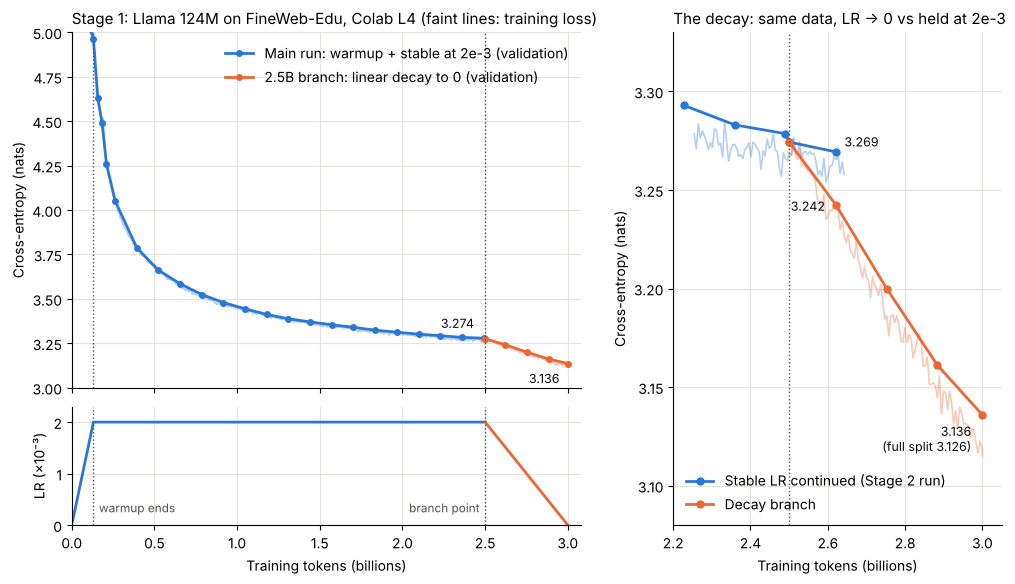

Milestone                                | Tokens | Val loss | Full split
Main, step 400 (sweep at 2e-3: 4.2196)   |  0.21B |   4.2599 |          —
Main, step 4,768 (pre-decay)             |  2.50B |   3.2743 |          —
2.5B model, step 5,722                   |  3.00B |   3.1359 |     3.1258

The decay lowered validation loss by 0.138 nats.
At step 5,000 on the same data: decaying 3.2423, stable 3.2693.

Rollbacks: 0. Largest gradient norm after step 100 of warmup: 11.6 (steps 221–230). After step 400: max 0.33, 0 clipped steps.
Speed: median 40,348 tokens/s, MFU 23.8%; about 20.7 h of training for 3.00B tokens (2.14e+18 FLOPs).

The same prompt during Stage 1 (temperature 0.8, top-p 0.9):
  [main 1,000] 'The water cycle begins when the water level drops.\nPayment begins to become stagnant, even though there are no water to maintain its purity.\n|Baggar||Old, clear water has started to form. These days, you will not want to be too tidy. So you may not want to'
  [main 2,000] 'The wa

In [ ]:
# Stage 1 summary: the main run up to the branch point and the 2.5B decay branch, read from Drive.
STAGE1_END = BRANCH_AT_STEP + BRANCH_DECAY_STEPS


def stage1_summary():
    main, branch = track_metrics('main'), track_metrics('branch')
    card = read_json(MODELS_DIR / MODEL_NAMES['branch'] / 'model.json')
    if not (main and branch and card and branch['status'] == 'complete'):
        print('Stage 1 is not finished yet.')
        return None
    GB = 1e9
    mt = [r for r in main['train'] if r['step'] <= BRANCH_AT_STEP]
    mv = [r for r in main['val'] if 0 < r['step'] <= BRANCH_AT_STEP]
    bt, bv = branch['train'], branch['val']
    INK, INK2, GRID, BLUE, ORANGE = '#0b0b0b', '#52514e', '#e4e3df', '#2a78d6', '#eb6834'
    lr_text = f'{PEAK_LR:.0e}'.replace('e-0', 'e-')   # 2e-3

    fig = plt.figure(figsize=(12, 6.4))
    grid = fig.add_gridspec(2, 2, width_ratios=[1.55, 1], height_ratios=[3, 1], hspace=0.08, wspace=0.22)
    ax, ax_lr, ax_zoom = fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[:, 1])
    for a in (ax, ax_lr, ax_zoom):
        a.spines[['top', 'right']].set_visible(False)
        a.grid(color=GRID, linewidth=0.8)
        a.set_axisbelow(True)

    # Left: the whole of Stage 1, with the learning rate below it.
    for rows, color in ((mt, BLUE), (bt, ORANGE)):
        ax.plot([r['tokens'] / GB for r in rows], [r['loss'] for r in rows], color=color, alpha=0.35, linewidth=1.2)
    ax.plot([r['tokens'] / GB for r in mv], [r['val_loss'] for r in mv], color=BLUE, linewidth=2, marker='o',
            markersize=4, label=f'Main run: warmup + stable at {lr_text} (validation)')
    ax.plot([r['tokens'] / GB for r in bv], [r['val_loss'] for r in bv], color=ORANGE, linewidth=2, marker='o',
            markersize=4, label='2.5B branch: linear decay to 0 (validation)')
    for point, offset in ((mv[-1], (-8, 8)), (bv[-1], (-6, -14))):
        ax.annotate(f'{point["val_loss"]:.3f}', (point['tokens'] / GB, point['val_loss']), xytext=offset,
                    textcoords='offset points', ha='right', color=INK, fontsize=9)
    ax.set(xlim=(0, 3.08), ylim=(3.0, 5.0), ylabel='Cross-entropy (nats)')
    ax.set_title(f'Stage 1: Llama 124M on FineWeb-Edu, Colab {GPU_TAG.upper()} (faint lines: training loss)',
                 loc='left', fontsize=11)
    ax.tick_params(labelbottom=False)
    ax.legend(frameon=False, loc='upper right')
    ax_lr.plot([r['tokens'] / GB for r in mt], [r['lr'] * 1e3 for r in mt], color=BLUE, linewidth=2)
    ax_lr.plot([r['tokens'] / GB for r in bt], [r['lr'] * 1e3 for r in bt], color=ORANGE, linewidth=2)
    ax_lr.set(xlim=(0, 3.08), ylim=(0, 2.3), ylabel='LR (×10⁻³)', xlabel='Training tokens (billions)')
    for step, text, dx, ha in ((WARMUP_STEPS, 'warmup ends', 4, 'left'), (BRANCH_AT_STEP, 'branch point', -4, 'right')):
        x = step * TOKENS_PER_STEP / GB
        for a in (ax, ax_lr):
            a.axvline(x, color=INK2, linestyle=':', linewidth=1)
        ax_lr.annotate(text, (x, 0.25), xytext=(dx, 0), textcoords='offset points', ha=ha, color=INK2, fontsize=8.5)

    # Right: the decay against the main run carrying on at the stable rate, on the same data.
    late = [r for r in main['train'] if r['step'] > BRANCH_AT_STEP - 470]
    ax_zoom.plot([r['tokens'] / GB for r in late], [r['loss'] for r in late], color=BLUE, alpha=0.35, linewidth=1.2)
    ax_zoom.plot([r['tokens'] / GB for r in bt], [r['loss'] for r in bt], color=ORANGE, alpha=0.35, linewidth=1.2)
    zoom_main = [r for r in main['val'] if r['step'] >= BRANCH_AT_STEP - 518]
    ax_zoom.plot([r['tokens'] / GB for r in zoom_main], [r['val_loss'] for r in zoom_main], color=BLUE, linewidth=2,
                 marker='o', markersize=5, label='Stable LR continued (Stage 2 run)')
    ax_zoom.plot([r['tokens'] / GB for r in bv], [r['val_loss'] for r in bv], color=ORANGE, linewidth=2, marker='o',
                 markersize=5, label='Decay branch')
    both = sorted({r['step'] for r in main['val']} & {r['step'] for r in bv} - {BRANCH_AT_STEP})
    if both:
        same_main = next(r for r in main['val'] if r['step'] == both[0])
        same_branch = next(r for r in bv if r['step'] == both[0])
        ax_zoom.annotate(f'{same_main["val_loss"]:.3f}', (same_main['tokens'] / GB, same_main['val_loss']),
                         xytext=(6, 4), textcoords='offset points', color=INK, fontsize=9)
        ax_zoom.annotate(f'{same_branch["val_loss"]:.3f}', (same_branch['tokens'] / GB, same_branch['val_loss']),
                         xytext=(-8, -4), textcoords='offset points', ha='right', color=INK, fontsize=9)
    ax_zoom.annotate(f'{bv[-1]["val_loss"]:.3f}\n(full split {card["full_split_val_loss"]:.3f})',
                     (bv[-1]['tokens'] / GB, bv[-1]['val_loss']), xytext=(-8, -26), textcoords='offset points',
                     ha='right', color=INK, fontsize=9)
    ax_zoom.axvline(BRANCH_AT_STEP * TOKENS_PER_STEP / GB, color=INK2, linestyle=':', linewidth=1)
    ax_zoom.set(xlim=(2.2, 3.05), ylim=(3.08, 3.33), xlabel='Training tokens (billions)', ylabel='Cross-entropy (nats)')
    ax_zoom.set_title(f'The decay: same data, LR → 0 vs held at {lr_text}', loc='left', fontsize=11)
    ax_zoom.legend(frameon=False, loc='lower left')
    plot_path = RUN_DIR / 'stage1_training_curves.png'
    fig.savefig(plot_path, dpi=160, bbox_inches='tight')
    plt.show()

    # Milestones, health and speed.
    def val_at(rows, step):
        return next(r['val_loss'] for r in rows if r['step'] == step)

    print(f'{"Milestone":<40} | {"Tokens":>6} | {"Val loss":>8} | {"Full split":>10}')
    print(f'{"Main, step 400 (sweep at 2e-3: 4.2196)":<40} | {400 * TOKENS_PER_STEP / GB:>5.2f}B | '
          f'{val_at(main["val"], 400):>8.4f} | {"—":>10}')
    print(f'{f"Main, step {BRANCH_AT_STEP:,} (pre-decay)":<40} | {BRANCH_AT_STEP * TOKENS_PER_STEP / GB:>5.2f}B | '
          f'{val_at(main["val"], BRANCH_AT_STEP):>8.4f} | {"—":>10}')
    print(f'{f"2.5B model, step {card["step"]:,}":<40} | {card["tokens"] / GB:>5.2f}B | {card["val_loss"]:>8.4f} | '
          f'{card["full_split_val_loss"]:>10.4f}')
    print(f'\nThe decay lowered validation loss by {val_at(main["val"], BRANCH_AT_STEP) - card["val_loss"]:.3f} nats.')
    if both:
        print(f'At step {both[0]:,} on the same data: decaying {same_branch["val_loss"]:.4f}, '
              f'stable {same_main["val_loss"]:.4f}.')
    rows = mt + bt
    events = main['events'] + branch['events']
    clipped_late = sum(r['clipped'] for r in rows if r['step'] > 400)
    peak_late = max(r['max_grad_norm'] for r in rows if r['step'] > 400)
    peak_warmup = max((r for r in mt if 100 < r['step'] <= 400), key=lambda r: r['max_grad_norm'])
    print(f'\nRollbacks: {len(events)}. Largest gradient norm after step 100 of warmup: '
          f'{peak_warmup["max_grad_norm"]:.1f} (steps {peak_warmup["step"] - 9}–{peak_warmup["step"]}). '
          f'After step 400: max {peak_late:.2f}, {clipped_late} clipped steps.')
    speeds = [r['tokens_per_second'] for r in rows]
    seconds = sum(LOG_EVERY * TOKENS_PER_STEP / r['tokens_per_second'] for r in rows)
    speed = float(np.median(speeds))
    peak = PEAK_BF16_FLOPS.get(GPU_TAG.removesuffix('-80gb'))
    print(f'Speed: median {speed:,.0f} tokens/s' + (f', MFU {speed * FLOPS_PER_TOKEN / peak:.1%}' if peak else '')
          + f'; about {seconds / 3600:.1f} h of training for {card["tokens"] / GB:.2f}B tokens '
          f'({card["tokens"] * FLOPS_PER_TOKEN:.2e} FLOPs).')

    print('\nThe same prompt during Stage 1 (temperature 0.8, top-p 0.9):')
    stage1_samples = [s for s in main['samples'] if s['step'] < BRANCH_AT_STEP] + branch['samples']
    for s in stage1_samples:
        label = f'main {s["step"]:,}' if s in main['samples'] else f'branch {s["step"]:,}'
        print(f'  [{label}] {s["text"]!r}')
    print('\nThe 2.5B model:')
    for s in card['samples']:
        print(f'  {s["text"]!r}')
    print(f'\nSaved {plot_path}')
    return card


STAGE1 = stage1_summary()

### Files

On Drive, the run keeps everything under one folder:

```text
MyDrive/CS336_FineWebEdu_Llama124M/
  token_cache/                     # the sweep's cache (unchanged)
  token_cache_full/                # built once on a CPU runtime, ~20 GB
    manifest.json  tokenizer.json  valid.u16  train-000-001.u16  train-002.u16 … train-012.u16
  smoke_tests/full-<gpu>.json      # self-check results per GPU type
  runs/full_v1/
    run_config.json                # fixed settings and the schedule's history
    probe-<gpu>.json               # micro-batch, tokens/s, memory, MFU
    main/metrics.json              # losses, learning rate, gradient norms, samples, rollbacks
    branch/metrics.json            # the 2.5B branch
    checkpoints/                   # one rolling cs336-llama124m-full-<track>-step….pt (1.4 GB)
    pre_decay/                     # the permanent step-4,768 checkpoint (1.4 GB)
    models/2.5B/                   # cs336-llama124m-2.5B-fp16.pt (0.23 GB), tokenizer.json, model.json
    models/final/                  # cs336-llama124m-final-fp16.pt (Stage 2)
    stage1_training_curves.png
```

The repo keeps the small files in [`runs/full_v1/`](runs/full_v1/): `run_config.json`, `probe-l4.json` and the cache manifest, and in `stage1_2.5B/`, the main run's metrics up to step 4,768, the branch's metrics, the model card and the plot. The model weights stay on Drive until Stage 2. Then both models get a GitHub release, with generated text compared side by side, as in Track 1.

**Next:** Stage 2 continues the main run to 10B tokens in this same notebook. Its record will be `CS336_FineWebEdu_Llama124M_Trained_Stage_2.ipynb`.

[FineWeb-Edu](https://huggingface.co/datasets/HuggingFaceFW/fineweb-edu) · [Stanford CS336](https://cs336.stanford.edu/) · [CMU 11-711 Build Your Own Llama](https://cmu-l3.github.io/anlp-fall2025/assignments/assignment1) · [WSD schedule (MiniCPM)](https://arxiv.org/abs/2404.06395) · [PaLM, on skipping batches around loss spikes](https://arxiv.org/abs/2204.02311)